# Coding Note 6 — From Gradients to Neural Networks

**Reading route:** first read the concept and its picture. Detailed formulas, gradient calculations and fixed-parameter network arithmetic are optional reference for later work. The lecture teaches the intuition behind these methods.

This complete reference notebook follows **vectors → gradients → gradient descent → Gradient Boosting → SVM/SVR → neural-network layers and learning → LSTM for sequences**. Examples 6.1–6.15, including the added Example 6.8A, generate all figures in the revised lecture notes and slides. Each code step has explanatory Markdown, fixed illustrative inputs, outputs and a work-reference paragraph.

All generated datasets here are small, explicitly constructed teaching examples. Neural-network and LSTM cells are fixed-parameter forward/gradient illustrations. Fitting examples for boosting, SVM and SVR demonstrate mechanics; workplace evaluation still uses the earlier lectures' appropriate held-out or chronological design. Project requirements remain the previously released four-model tasks, and Lecture 6 assigns no homework.

**How to use this reference later:** find the numbered concept; inspect its input shape, stated assumptions, parameter settings and figure; replace the illustrative data deliberately; apply training-only transformations and appropriate evaluation before interpreting results.

## 0.1 — Libraries, paths and figure output

Use NumPy for numeric arrays, matplotlib for diagrams and scikit-learn for the small tree/SVM illustrations. All data below are constructed locally. `figures` are saved and displayed in the notebook; numerical summaries are written to `Coding Part/bridge_outputs`.

In [1]:
from pathlib import Path
import json, importlib.util
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib import colors
from IPython.display import display, Image as NotebookImage
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVC, SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from pathlib import Path
REPOSITORY_ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                       if (folder / 'Coding_Notes').is_dir())
NOTEBOOK_ROOT = REPOSITORY_ROOT / 'Coding_Notes'
C=REPOSITORY_ROOT
P=NOTEBOOK_ROOT/'outputs/Lecture_06';Q=P/'tables';G=P/'figures'
Q.mkdir(parents=True,exist_ok=True);G.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.size':12,'legend.frameon':False,'axes.labelsize':14})
BLUE,ORANGE,GREEN='#0072B2','#D55E00','#009E73'
values={}
def save(n):
 plt.tight_layout();plt.savefig(G/f'ex6_{n:02}.png',dpi=180,facecolor='white');display(NotebookImage(filename=str(G/f'ex6_{n:02}.png')));plt.close()

## Example 6.1 — A vector keeps several numbers in a stated order

A scalar is one number. A vector is an ordered list of numbers. Each position is a coordinate; the number of positions is its dimension. A two-coordinate vector can be drawn as an arrow from the origin. A dot product multiplies matching coordinates and adds the products.

Imagine a shop records today's customer count and average spending. These are two different measurements kept in a fixed order. A vector is the list holding them. The two axes in our small picture simply give each list position its own direction.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ \mathbf{x}=(x_1,x_2),\qquad \mathbf{w}\cdot\mathbf{x}=w_1x_1+w_2x_2 $$

**x coordinates:** two input values in a fixed order

**w coordinates:** weights paired with those inputs

**dot product:** one weighted sum

### 6.1.1 — Construct an input and a weight vector

**Purpose and inputs.** Use two standardized illustrative inputs, x=(2,1), and weights w=(3,-1).

**Read the result.** The weighted sum is 5; reordering only the inputs changes its meaning.

In [2]:
x=np.array([2.,1.]);w=np.array([3.,-1.]);score=float(w@x)
print('Input:',x,'Weights:',w,'Weighted sum:',score)
assert score==5

Input: [2. 1.] Weights: [ 3. -1.] Weighted sum: 5.0


### 6.1.2 — Draw the labeled input arrow

**Purpose and inputs.** Use fixed axes with one unit per coordinate.

**Read the result.** The arrow endpoint contains the two values in order.

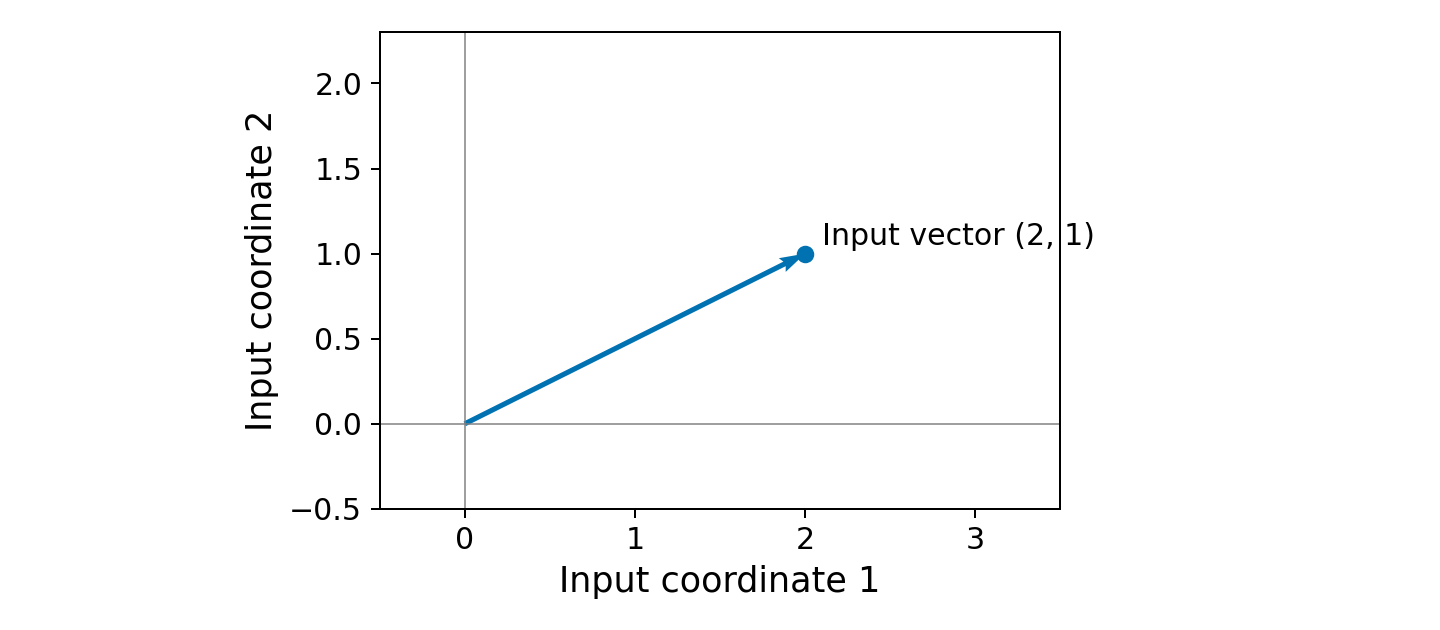

In [3]:
fig,ax=plt.subplots(figsize=(8,3.5));ax.quiver(0,0,*x,angles='xy',scale_units='xy',scale=1,color=BLUE);ax.scatter(*x,color=BLUE);ax.text(2.1,1.05,'Input vector (2, 1)',color='black');ax.set(xlim=(-.5,3.5),ylim=(-.5,2.3),xlabel='Input coordinate 1',ylabel='Input coordinate 2');ax.axhline(0,color='gray',lw=.6);ax.axvline(0,color='gray',lw=.6);ax.set_aspect('equal');save(1)
values['6.1']={'x':x.tolist(),'w':w.tolist(),'dot':score}

### Interpretation

An input vector, parameter vector and gradient vector have different meanings even when each has two coordinates. Labels and units determine what each arrow represents. Physical arrow lengths depend on coordinate scales.

### When to refer back at work

Refer here when checking the order of columns in a model input or interpreting a weighted score. Keep variable names and units with the array.

## Example 6.2 — A gradient describes local changes in loss

A gradient describes how prediction error responds to small changes in model settings. It helps choose a direction for the next adjustment.

Imagine two knobs controlling a fitted line: one raises the whole line, and the other tilts it. Each position on the floor of this picture chooses both knob settings. The height shows the prediction error for that choice. To understand a local rate, turn just one knob a tiny amount and observe how much the error changes. A derivative records this small-change response; a partial derivative checks one knob at a time.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ J(a,b)=\frac{1}{3}\sum_{i=1}^{3}(a+bx_i-y_i)^2,\qquad \nabla J=(J_a,J_b) $$

**a and b:** the intercept and slope of a line

**J:** mean squared error on three training pairs

**gradient coordinates:** local loss changes along the intercept and slope directions

### 6.2.1 — Define a line and its training loss

**Purpose and inputs.** Use x=(0,1,2), y=(1,3,5), and initial intercept and slope zero.

**Read the result.** The zero prediction line has mean squared error 11.6667.

In [4]:
gx=np.array([0.,1.,2.]);gy=np.array([1.,3.,5.])
def loss(theta):return float(np.mean((theta[0]+theta[1]*gx-gy)**2))
def gradient(theta):
 err=theta[0]+theta[1]*gx-gy
 return np.array([2*err.mean(),2*np.mean(err*gx)])
theta0=np.array([0.,0.]);grad0=gradient(theta0)
print('Initial loss:',loss(theta0),'Gradient:',grad0)

Initial loss: 11.666666666666666 Gradient: [-6.         -8.66666667]


### 6.2.2 — Check the local slopes numerically

**Purpose and inputs.** Perturb one parameter at a time by a small amount.

**Read the result.** Finite differences agree with the two computed gradient coordinates.

In [5]:
eps=1e-5
numeric=np.array([(loss(theta0+eps*np.eye(2)[j])-loss(theta0-eps*np.eye(2)[j]))/(2*eps) for j in range(2)])
assert np.allclose(numeric,grad0,atol=1e-7)
print('Numeric local slopes:',numeric)

Numeric local slopes: [-6.         -8.66666667]


### 6.2.3 — Draw the loss bowl and opposite arrows

**Purpose and inputs.** Evaluate the same loss on a fixed parameter grid.

**Read the result.** The gradient arrow rises locally; its opposite points toward a local decrease.

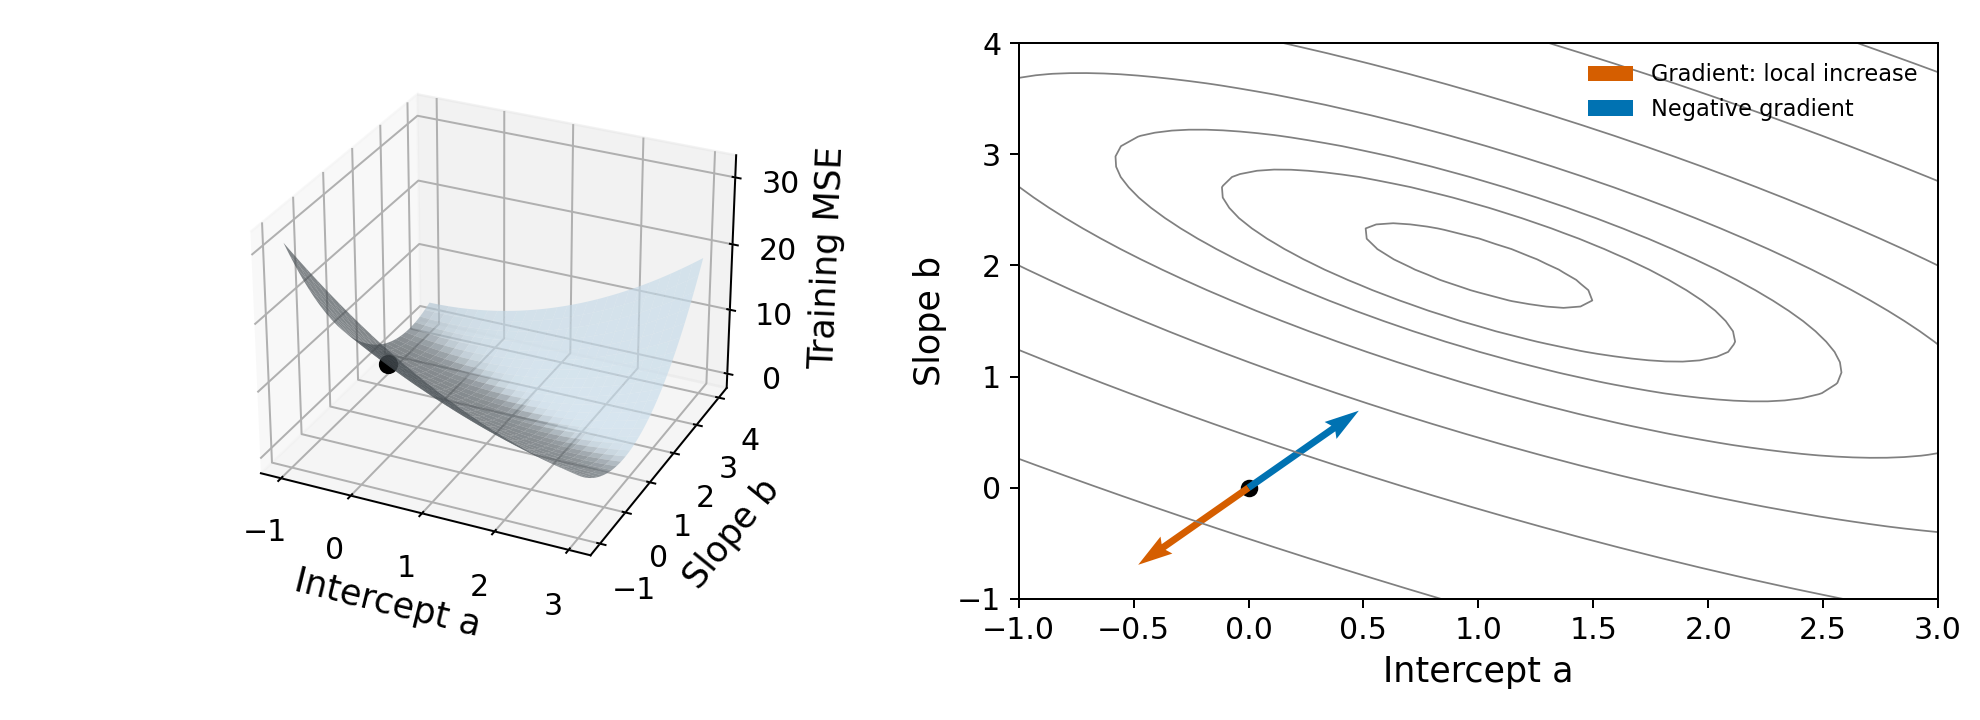

In [6]:
aa,bb=np.meshgrid(np.linspace(-1,3,55),np.linspace(-1,4,55));zz=np.mean((aa[...,None]+bb[...,None]*gx-gy)**2,axis=-1)
fig=plt.figure(figsize=(11,4));ax=fig.add_subplot(121,projection='3d');ax.plot_surface(aa,bb,zz,color='#c7ddec',alpha=.65,linewidth=0);ax.scatter(0,0,loss(theta0),color='black',s=45);ax.set(xlabel='Intercept a',ylabel='Slope b',zlabel='Training MSE');ax.view_init(28,-65)
ax2=fig.add_subplot(122);ax2.contour(aa,bb,zz,levels=[.1,.5,1,2,4,8,16,32],colors='gray',linewidths=.7);ax2.scatter(0,0,color='black');ax2.quiver(0,0,*(.08*grad0),angles='xy',scale_units='xy',scale=1,color=ORANGE,label='Gradient: local increase');ax2.quiver(0,0,*(-.08*grad0),angles='xy',scale_units='xy',scale=1,color=BLUE,label='Negative gradient');ax2.set(xlim=(-1,3),ylim=(-1,4),xlabel='Intercept a',ylabel='Slope b');ax2.legend(fontsize=9);save(2)
values['6.2']={'initial_loss':loss(theta0),'gradient':grad0.tolist()}

### Interpretation

The loss surface has intercept and slope on its two horizontal axes and loss on its vertical axis. The gradient points toward steepest local increase in the chosen parameter coordinates. Its negative provides a local decrease direction for a sufficiently small update.

### When to refer back at work

Refer here to distinguish model parameters from input features, inspect a gradient sign or check whether an optimizer is moving uphill or downhill.

## Example 6.3 — Gradient descent takes a scaled downhill step

Gradient descent repeatedly uses the local downhill direction to adjust a model by small steps.

Watch the moving point on the bowl. Its position gives the current two knob settings, and its height gives their loss. Each short move changes the settings and recalculates the loss. At the next position, calculate a fresh direction before moving again. That sequence of small downhill moves is gradient descent.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ \boldsymbol\theta_{k+1}=\boldsymbol\theta_k-\eta\nabla J(\boldsymbol\theta_k) $$

**current parameter vector:** the intercept and slope before an update

**gradient:** local loss-change vector at that position

**learning rate eta:** positive update-size multiplier

**new parameter vector:** current parameters minus the scaled gradient

### 6.3.1 — Compute one explicit update

**Purpose and inputs.** Start from the previous line and use learning rate .1.

**Read the result.** Subtracting the negative gradient coordinates increases both coefficients.

In [7]:
eta=.1;theta1=theta0-eta*grad0
print('Old:',theta0,'New:',theta1,'Old/new loss:',loss(theta0),loss(theta1))
assert loss(theta1)<loss(theta0)

Old: [0. 0.] New: [0.6        0.86666667] Old/new loss: 11.666666666666666 3.2074074074074073


### 6.3.2 — Repeat the update with a newly computed gradient

**Purpose and inputs.** Run 40 iterations on the same three training pairs.

**Read the result.** The path approaches intercept 1 and slope 2 for this convex quadratic example.

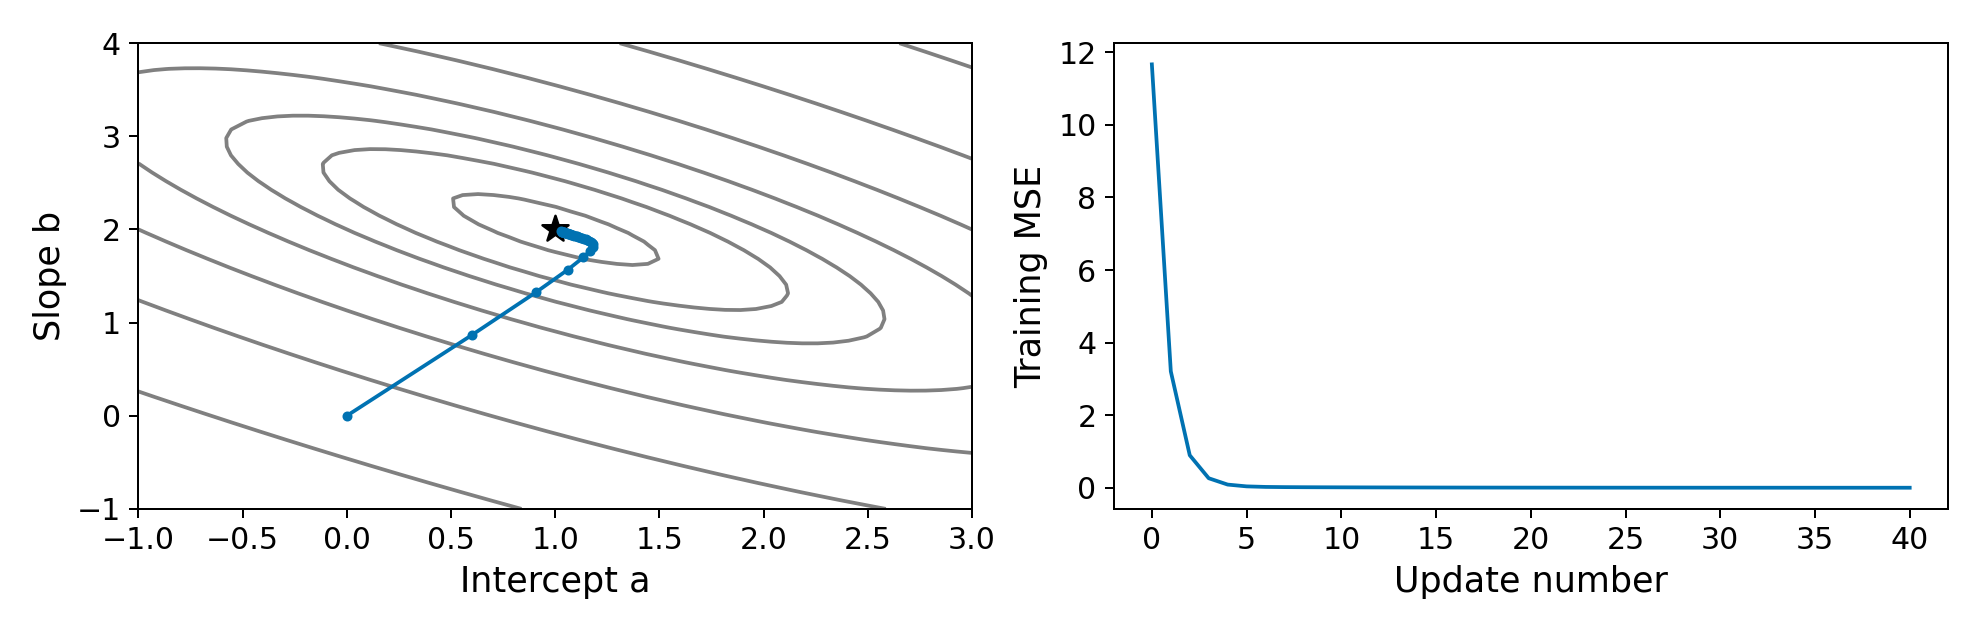

In [8]:
path=[theta0.copy()]
for _ in range(40):path.append(path[-1]-.1*gradient(path[-1]))
path=np.array(path);train_losses=np.array([loss(t) for t in path])
assert np.all(np.diff(train_losses)<0)
fig,axs=plt.subplots(1,2,figsize=(11,3.5));axs[0].contour(aa,bb,zz,levels=[.1,.5,1,2,4,8,16,32],colors='gray');axs[0].plot(path[:,0],path[:,1],'o-',ms=3,color=BLUE);axs[0].scatter(1,2,marker='*',s=120,color='black');axs[0].set(xlabel='Intercept a',ylabel='Slope b');axs[1].plot(train_losses,color=BLUE);axs[1].set(xlabel='Update number',ylabel='Training MSE');save(3)
values['6.3']={'first_parameters':theta1.tolist(),'first_loss':loss(theta1),'last_parameters':path[-1].tolist(),'last_loss':float(train_losses[-1])}
np.savez(Q/'gradient_path.npz',path=path,losses=train_losses)

### Interpretation

At the first step, eta=.1 moves (0,0) to (.6,.8667) and reduces MSE to about 3.2074. Recomputing the gradient at every new position updates the direction as well as the parameters.

### When to refer back at work

Refer here when reading an iterative training loop or diagnosing the sign and scale of a parameter update. Report training and later evaluation loss separately.

## Example 6.4 — Learning rate changes the size of the update

A learning rate controls how far an update moves for a given gradient. A large step can cross a low-loss region and increase loss. A small step can make progress slowly.

On this graph, a falling line means smaller training error as updates continue. The vertical axis uses a logarithmic scale: equal vertical gaps represent equal multiplication factors. This makes both very large errors and small errors visible in the same picture.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

### 6.4.1 — Hold the problem fixed and change eta

**Purpose and inputs.** Compare .01, .1 and 1 for 12 updates.

**Read the result.** Any loss increase is measured from the same starting parameters and data.

In [9]:
rate_paths={}
for rate in [.01,.1,1.]:
 t=theta0.copy();ls=[loss(t)]
 for _ in range(12):t=t-rate*gradient(t);ls.append(loss(t))
 rate_paths[str(rate)]=ls
print({r:ls[-1] for r,ls in rate_paths.items()})

{'0.01': 3.625921802404134, '0.1': 0.009021483152466016, '1.0': 815096147100372.6}


### 6.4.2 — Plot training loss on a logarithmic scale

**Purpose and inputs.** A log scale keeps the divergent path visible with the others.

**Read the result.** The axis label states that scale explicitly.

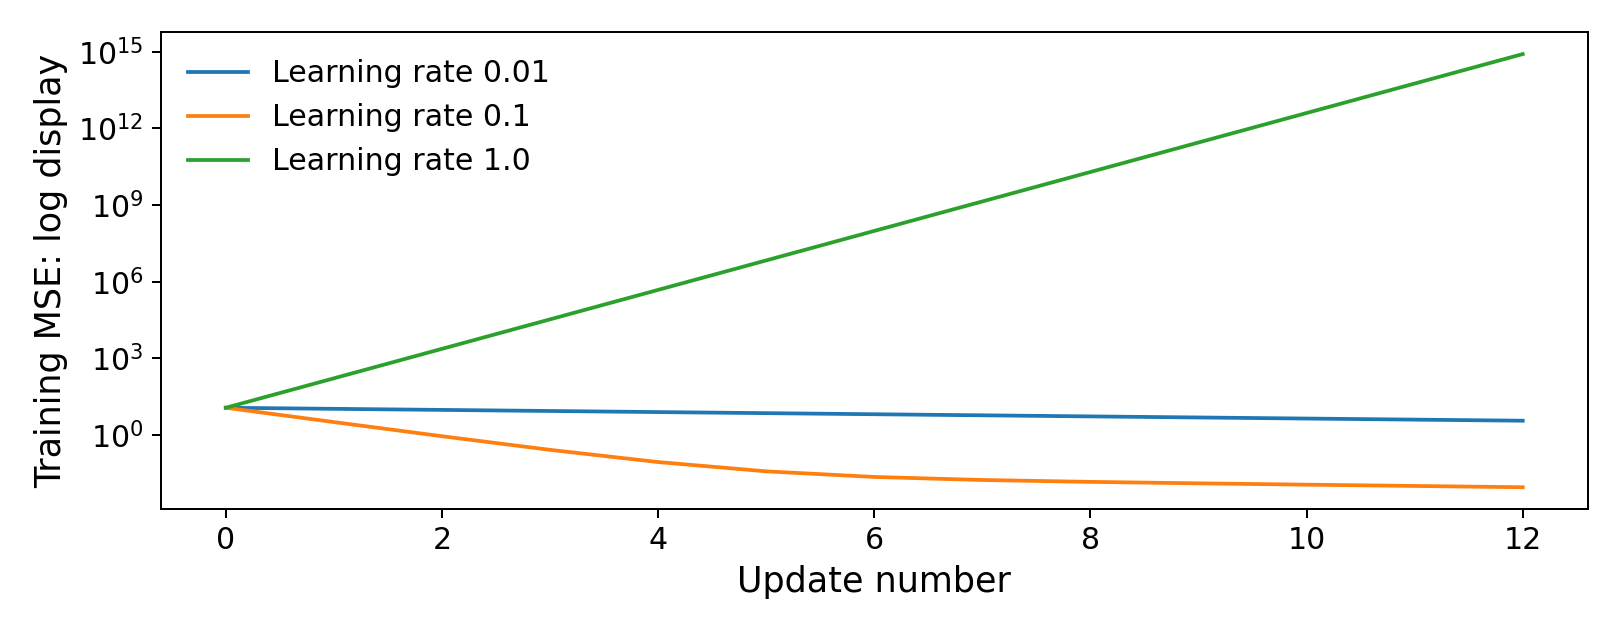

In [10]:
fig,ax=plt.subplots(figsize=(9,3.5))
for r,ls in rate_paths.items():ax.semilogy(ls,label='Learning rate '+r)
ax.set(xlabel='Update number',ylabel='Training MSE: log display');ax.legend();save(4)
values['6.4']={r:float(ls[-1]) for r,ls in rate_paths.items()}

### Interpretation

The three trajectories use the same loss and starting point. Only eta changes. They demonstrate slow progress, effective decrease and divergence in this particular numerical problem.

### When to refer back at work

Refer here when loss rises or oscillates during training. Inspect scaling and learning rate, and select settings using an appropriate validation procedure.

## Example 6.5 — Boosting adds a correction function

Gradient Boosting builds an ensemble by adding fitted correction functions in stages. With half squared-error loss, a residual is the negative gradient with respect to the current prediction, so a shallow tree can be fitted to those residuals.

Watch the black dots and blue predictions. The black dots are the outcomes we are trying to match; they stay still. The blue predictions begin at four. For outcomes at zero, move the predictions down; for outcomes at eight, move them up. Each small tree supplies another correction based on the errors that remain.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ F_{m+1}(x)=F_m(x)+\eta T_m(x) $$

**F current:** the current combined prediction rule

**T:** a newly fitted correction tree

**eta:** the fraction of its correction that is added

**new F:** the old rule plus the scaled correction

### 6.5.1 — Create two groups and the initial mean rule

**Purpose and inputs.** Eight ordered inputs have outcomes 0,0,0,0,8,8,8,8.

**Read the result.** The initial average forecast is 4 for every training input.

In [11]:
bx=np.arange(8,dtype=float).reshape(-1,1);by=np.array([0.,0.,0.,0.,8.,8.,8.,8.]);bf=np.full(8,by.mean());boost_stages=[bf.copy()];boost_trees=[]
print('Initial prediction:',bf)

Initial prediction: [4. 4. 4. 4. 4. 4. 4. 4.]


### 6.5.2 — Fit a shallow tree to the current residuals

**Purpose and inputs.** At each stage, fit a one-split tree to actual minus current prediction.

**Read the result.** The tree learns a correction conditional on the input, then half that correction is added.

In [12]:
for m in range(3):
 residual=by-bf;tree=DecisionTreeRegressor(max_depth=1,random_state=417).fit(bx,residual)
 bf=bf+.5*tree.predict(bx);boost_stages.append(bf.copy());boost_trees.append(tree)
print(pd.DataFrame(np.array(boost_stages)[:,[0,7]],columns=['Group A prediction','Group B prediction']))
boost_losses=[float(.5*np.mean((by-f)**2)) for f in boost_stages]
print('Half mean squared losses:',boost_losses)

   Group A prediction  Group B prediction
0                 4.0                 4.0
1                 2.0                 6.0
2                 1.0                 7.0
3                 0.5                 7.5
Half mean squared losses: [8.0, 2.0, 0.5, 0.125]


### 6.5.3 — Compare the prediction stages using fixed axes

**Purpose and inputs.** Show the same outcomes and rules at stages 0,1,3.

**Read the result.** Black outcomes remain fixed while blue predictions improve in this constructed training example.

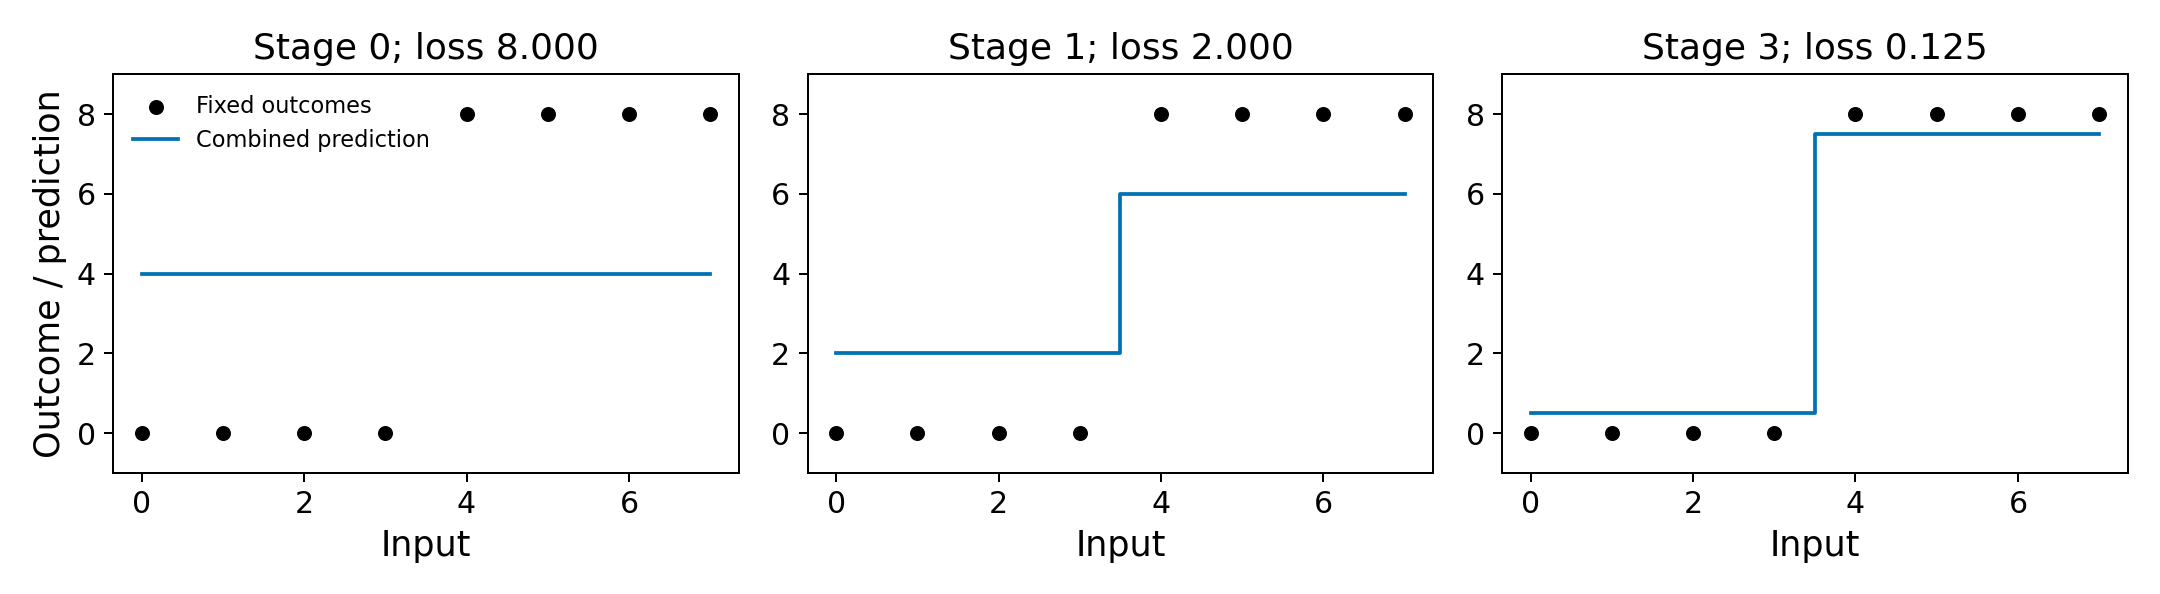

In [13]:
fig,axs=plt.subplots(1,3,figsize=(12,3.3))
for ax,m in zip(axs,[0,1,3]):
 ax.scatter(bx[:,0],by,color='black',s=25,label='Fixed outcomes');ax.step(bx[:,0],boost_stages[m],where='mid',color=BLUE,label='Combined prediction');ax.set(ylim=(-1,9),xlabel='Input',title=f'Stage {m}; loss {boost_losses[m]:.3f}')
axs[0].set_ylabel('Outcome / prediction');axs[0].legend(fontsize=9);save(5)
values['6.5']={'group_predictions':np.array(boost_stages)[:,[0,7]].tolist(),'losses':boost_losses}
np.savez(Q/'boosting_stages.npz',predictions=np.array(boost_stages),x=bx[:,0],y=by)

### 6.5.4 — Use the library implementation with the same settings

**Purpose and inputs.** GradientBoostingRegressor uses three one-split trees, learning rate .5 and squared-error loss.

**Read the result.** Its final predictions match the manual correction loop in this constructed example.

In [14]:
library_boost=GradientBoostingRegressor(n_estimators=3,learning_rate=.5,max_depth=1,loss='squared_error',random_state=417).fit(bx,by)
assert np.allclose(library_boost.predict(bx),boost_stages[-1])
print('Library predictions:',library_boost.predict(bx))

Library predictions: [0.5 0.5 0.5 0.5 7.5 7.5 7.5 7.5]


### Interpretation

The illustration starts from a constant mean prediction of 4. The true constructed values are 0 for the first group and 8 for the second. A shallow tree fits residuals (-4,+4); eta=.5 updates group predictions to (2,6), then (1,7), then (.5,7.5).

### When to refer back at work

Refer here to read a boosting implementation: identify the initial prediction, loss, residual/negative-gradient target, correction learner, learning rate and number of stages.

## Example 6.6 — Why the correction follows a negative gradient

For squared prediction errors, correcting the remaining signed errors takes predictions in a loss-reducing direction. This connects boosting to gradients.

In this bowl, the two floor directions now mean the predictions for the two groups. At four and four, the first prediction needs to fall and the second needs to rise. Follow the moving point as those two changes happen together. The point becomes lower because the predictions get closer to their observed outcomes. This connects the correction tree to the downhill idea behind the word gradient.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ \ell(y,F)=\tfrac12(y-F)^2,\qquad -\frac{\partial\ell}{\partial F}=y-F $$

**outcome y:** fixed observed training target

**current prediction F:** the value being corrected

**negative gradient:** the direction and size of the desired local correction

### 6.6.1 — Compute the two-coordinate prediction gradient

**Purpose and inputs.** Use one representative outcome from each of the two equal-sized groups.

**Read the result.** The negative gradient has coordinates (-4,+4) at the initial predictions (4,4), for the sum of the two half squared losses.

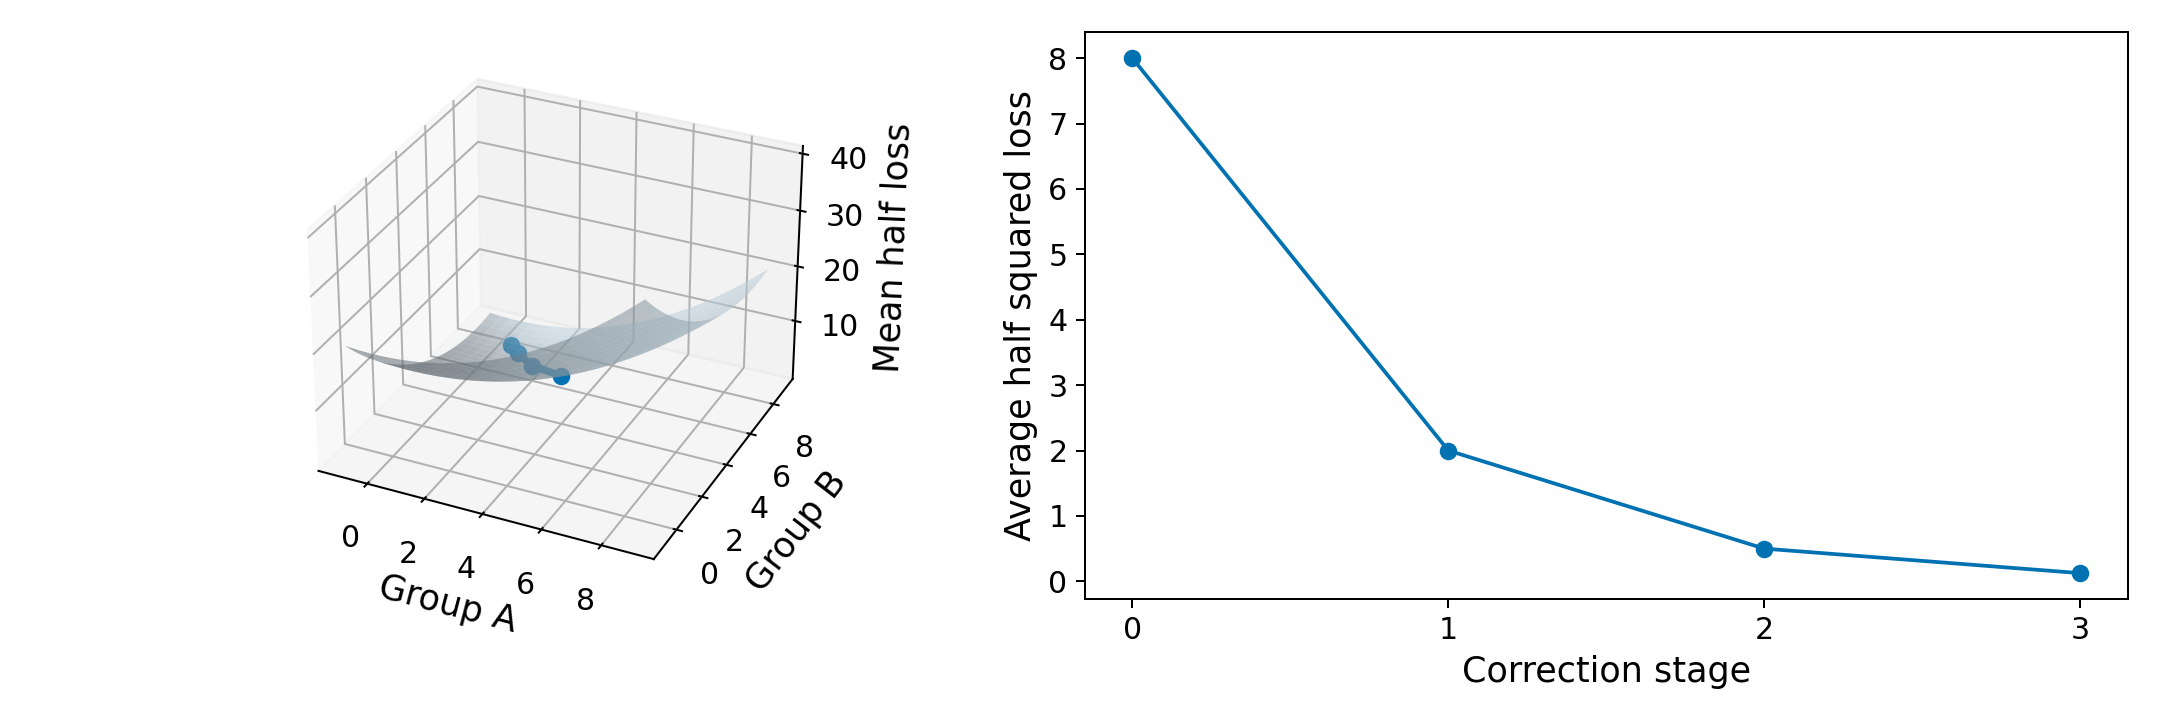

In [15]:
pred_path=np.array(boost_stages)[:,[0,7]];group_targets=np.array([0.,8.]);negative=group_targets-pred_path[0]
assert np.allclose(negative,[-4,4])
u,v=np.meshgrid(np.linspace(-1,9,55),np.linspace(-1,9,55));surf=.25*(u*u+(v-8)**2)
fig=plt.figure(figsize=(12,4));ax=fig.add_subplot(121,projection='3d');ax.plot_surface(u,v,surf,color='#c7ddec',alpha=.55,linewidth=0)
heights=np.array([.25*(p[0]**2+(p[1]-8)**2) for p in pred_path]);ax.plot(pred_path[:,0],pred_path[:,1],heights,'o-',color=BLUE,lw=3)
ax.set(xlabel='Group A',ylabel='Group B',zlabel='Mean half loss');ax.view_init(30,-65)
ax2=fig.add_subplot(122);ax2.plot(range(4),heights,'o-',color=BLUE);ax2.set(xlabel='Correction stage',ylabel='Average half squared loss',xticks=range(4));save(6)
values['6.6']={'initial_negative_gradient_sum_loss':negative.tolist(),'average_losses':heights.tolist()}

### Interpretation

The surface shown has Group A prediction and Group B prediction as its two horizontal axes. The path (4,4) → (2,6) → (1,7) → (.5,7.5) lowers their average half squared loss. A shallow tree captures that direction exactly in this simple two-group dataset. General corrections are constrained by the fitted learner and the chosen loss.

### When to refer back at work

Refer here to connect the name Gradient Boosting with its loss. Residual fitting is the squared-error instance; other losses supply their own negative-gradient targets.

## Example 6.7 — SVM learns a separating boundary and a margin

A support vector machine (SVM) learns a boundary between categories. Its margin is a strip around that boundary; supporting observations help determine it.

Imagine each dot represents a customer, located using two recorded measurements. Its color shows one of two known categories. A boundary is a dividing line: a new customer's side of the line determines the predicted category. The margin is the empty strip around the dividing line. The nearest supporting dots constrain how wide that strip can be. With overlapping categories, the setting C controls how strongly the fitted model penalizes points that cross a strip edge or end up on the wrong side.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ s(\mathbf{x})=\mathbf{w}\cdot\mathbf{x}+b $$

**input vector:** the two measured coordinates of one observation

**weights and intercept:** the learned boundary parameters

**score sign:** the side of the decision boundary, used to assign a class

### 6.7.1 — Fit a linear SVM on a small two-category sample

**Purpose and inputs.** Construct separated points and fit a linear kernel with C=10. A linear kernel uses ordinary dot-product similarity between the input vectors.

**Read the result.** The learned score is zero on the decision line and has opposite signs on its two sides.

In [16]:
sx=np.array([[-2.,-1.],[-1.5,-1.5],[-1.,-.4],[1.,.4],[1.5,1.5],[2.,1.]])
sy=np.array([0,0,0,1,1,1]);svm=SVC(kernel='linear',C=10).fit(sx,sy)
print('Boundary weights:',svm.coef_,'Intercept:',svm.intercept_,'Support observations:',svm.support_)

Boundary weights: [[0.86206898 0.34482759]] Intercept: [-0.] Support observations: [2 3]


### 6.7.2 — Draw the boundary, margin and supporting observations

**Purpose and inputs.** Use contours of fitted score -1,0,+1.

**Read the result.** The circled observations determine the fitted support-vector rule.

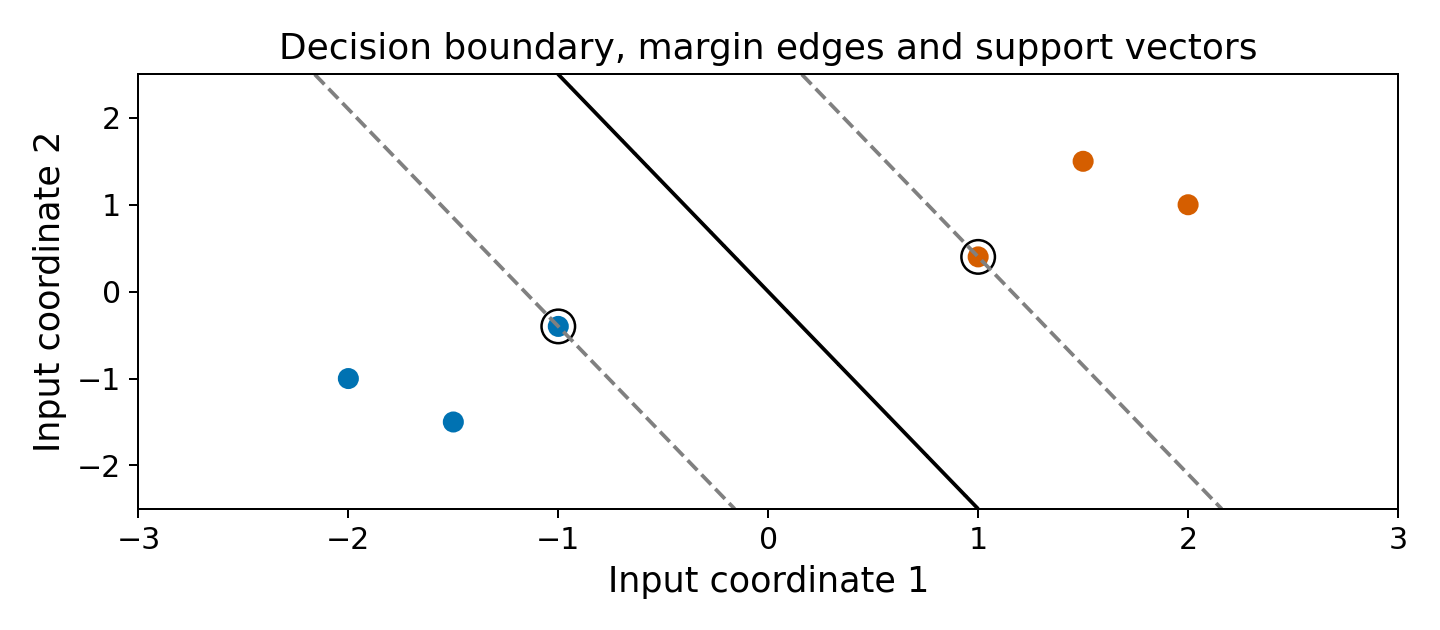

In [17]:
xx,yy=np.meshgrid(np.linspace(-3,3,100),np.linspace(-2.5,2.5,100));scores=svm.decision_function(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
fig,ax=plt.subplots(figsize=(8,3.5));ax.scatter(sx[:,0],sx[:,1],c=np.where(sy==0,BLUE,ORANGE),s=55);ax.contour(xx,yy,scores,levels=[-1,0,1],colors=['gray','black','gray'],linestyles=['--','-','--']);ax.scatter(svm.support_vectors_[:,0],svm.support_vectors_[:,1],facecolors='none',edgecolors='black',s=180);ax.set(xlabel='Input coordinate 1',ylabel='Input coordinate 2',title='Decision boundary, margin edges and support vectors');save(7)
values['6.7']={'weights':svm.coef_[0].tolist(),'intercept':float(svm.intercept_[0]),'support_indices':svm.support_.tolist()}

### Interpretation

The two colors indicate two categories, not good and bad outcomes. The fitted linear SVM separates this constructed sample. Its C parameter balances margin size with penalties for margin violations. Model settings and classification performance require evaluation on appropriate held-out observations in an applied task.

### When to refer back at work

Refer here when your outcome is a category and you need to understand an SVM boundary, support vectors or the C parameter. Standardize differently scaled inputs inside the training/validation workflow.

## Example 6.8 — A feature map can make a curved boundary simpler

A feature is an input measurement or a number calculated from measurements. A feature map calculates new inputs that can make a boundary easier to draw.

Look at the inner and outer rings of dots. A single straight line across the flat picture cannot separate the complete inner ring from the outer ring. Add a height equal to each dot's squared distance from the center. The outer ring rises higher. A flat shelf placed between the two heights now separates them. The added height is a newly calculated input, called a feature. A feature map specifies how to calculate such new inputs from the original measurements.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ \phi(x_1,x_2)=(x_1,x_2,x_1^2+x_2^2) $$

**original coordinates:** the two inputs before transformation

**new third coordinate:** squared distance from the center

**lifted space:** the transformed observations drawn in three dimensions

### 6.8.1 — Construct two circles and the third coordinate

**Purpose and inputs.** Use 16 observations per circle with radii 1 and 2.

**Read the result.** The third coordinate separates the groups in height.

In [18]:
angle=np.linspace(0,2*np.pi,16,endpoint=False);circle=np.vstack([np.c_[np.cos(angle),np.sin(angle)],2*np.c_[np.cos(angle),np.sin(angle)]]);labels=np.repeat([0,1],16);radius2=np.sum(circle**2,axis=1)
lifted=np.c_[circle,radius2];plane=SVC(kernel='linear',C=10).fit(radius2.reshape(-1,1),labels);cut=float(-plane.intercept_[0]/plane.coef_[0,0]);print('Separating squared-radius cutoff:',cut)

Separating squared-radius cutoff: 2.5000000000000004


### 6.8.2 — Display the original circles and lifted plane

**Purpose and inputs.** Show actual mapped coordinates with fixed axes.

**Read the result.** The plane separates the constructed transformed observations.

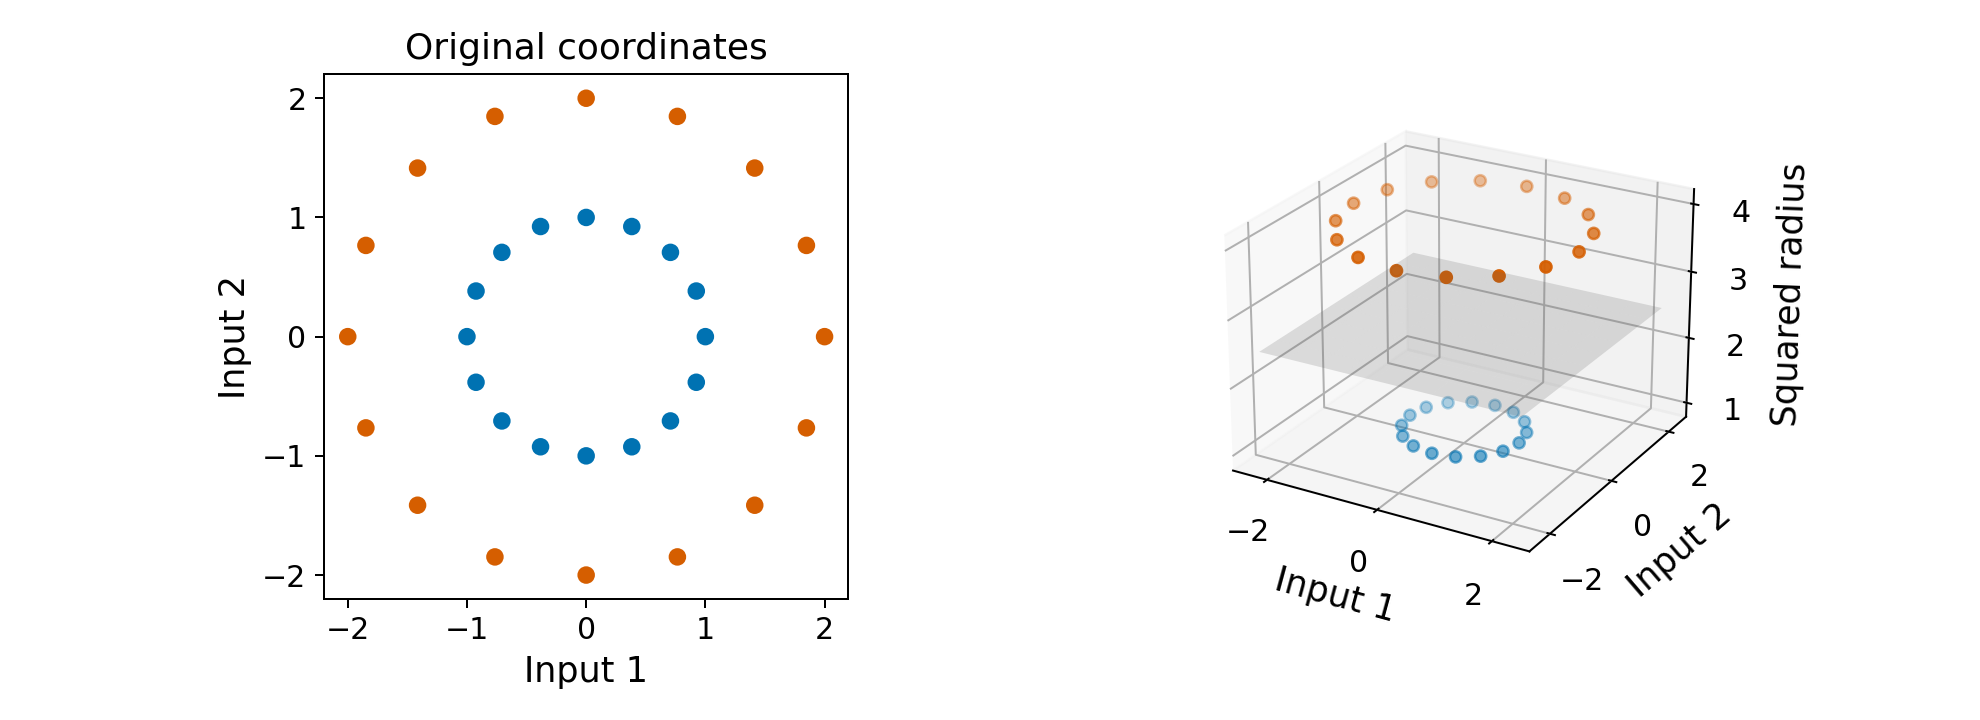

In [19]:
fig=plt.figure(figsize=(11,4));ax=fig.add_subplot(121);ax.scatter(circle[:,0],circle[:,1],c=np.where(labels==0,BLUE,ORANGE));ax.set(xlabel='Input 1',ylabel='Input 2',aspect='equal',title='Original coordinates')
ax=fig.add_subplot(122,projection='3d');ax.scatter(*lifted.T,c=np.where(labels==0,BLUE,ORANGE));px,py=np.meshgrid(np.linspace(-2.3,2.3,10),np.linspace(-2.3,2.3,10));ax.plot_surface(px,py,np.full_like(px,cut),color='gray',alpha=.2);ax.set(xlabel='Input 1',ylabel='Input 2',zlabel='Squared radius');ax.view_init(24,-60);save(8)
values['6.8']={'plane_cutoff':cut}
np.savez(Q/'svm_geometry.npz',points=sx,classes=sy,weights=svm.coef_[0],intercept=svm.intercept_[0],circle=circle,circle_labels=labels,lifted=lifted,cut=cut)

### Interpretation

Inner-circle points have radius one and squared radius one; outer-circle points have radius two and squared radius four. Their added coordinate makes separation by a horizontal plane possible. The explicit map is one transparent illustration of transformed coordinates.

### When to refer back at work

Refer here when investigating whether a nonlinear decision boundary or engineered features may help. Keep the transformation and its fitted parameters inside the appropriate training workflow.

## Example 6.8A — Gaussian kernel: nearby points have more influence

A Gaussian kernel assigns more weight or similarity to nearby inputs and less to distant inputs. Its width controls how quickly influence falls with distance.

Imagine estimating demand at a temperature of sixteen degrees. Read the two panels together. The upper panel contains observed temperatures and demand. The lower panel shows a Gaussian kernel, a bell-shaped rule for assigning weights around the temperature we care about. Observations near its centre receive larger weights. Their dots above become larger, showing their greater influence. Farther observations receive smaller weights. To form the orange weighted average, multiply each observed demand by its share of the total weight, then add the contributions. Now move the centre to a warmer temperature. The high-weight observations change, and the average changes with them. Keep the centre fixed and widen the bell. More distant observations now contribute more. This width controls how local the averaging is. In a support vector machine, the same Gaussian shape can measure similarity: nearby inputs are more similar. The SVM combines those similarities using coefficients learned during fitting. Our two-panel average makes the distance-to-weight idea visible; the SVM uses that similarity idea to learn its boundary.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ k_i=\exp[-(x_i-c)^2/(2h^2)],\quad p_i=k_i/\sum_j k_j,\quad \hat y(c)=\sum_i p_i y_i $$

**centre c:** temperature where a local average is requested

**width h:** distance scale of the weighting bell

**raw kernel weight k:** proximity-based influence before normalization

**weight share p:** fraction of total weight assigned to each observation

### 6.8A.1 — Calculate distance weights and their shares

**Purpose and inputs.** Use nine explicitly constructed days with temperature and demand.

**Read the result.** Weights sum to one after normalization; the local average remains in the observed demand range.

In [20]:
kernel_x=np.arange(12.,29.,2.)
kernel_y=np.array([32.,40.,37.,57.,61.,68.,86.,82.,91.])
centre,width=16.,2.
raw=np.exp(-.5*((kernel_x-centre)/width)**2);shares=raw/raw.sum()
print(pd.DataFrame({'temperature':kernel_x,'demand':kernel_y,'relative_weight':raw,'weight_share':shares}))
print('Weighted average:',shares@kernel_y)
from sklearn.metrics.pairwise import rbf_kernel
assert np.allclose(raw,rbf_kernel(kernel_x[:,None],np.array([[centre]]),gamma=1/(2*width**2))[:,0])
assert np.isclose(shares.sum(),1) and kernel_y.min() <= shares@kernel_y <= kernel_y.max()
np.savez(Q/'kernel_weights.npz',x=kernel_x,y=kernel_y)

   temperature  demand  relative_weight  weight_share
0         12.0    32.0     1.353353e-01  5.423868e-02
1         14.0    40.0     6.065307e-01  2.430809e-01
2         16.0    37.0     1.000000e+00  4.007727e-01
3         18.0    57.0     6.065307e-01  2.430809e-01
4         20.0    61.0     1.353353e-01  5.423868e-02
5         22.0    68.0     1.110900e-02  4.452182e-03
6         24.0    86.0     3.354626e-04  1.344443e-04
7         26.0    82.0     3.726653e-06  1.493541e-06
8         28.0    91.0     1.522998e-08  6.103760e-09
Weighted average: 43.76606900097621


### 6.8A.2 — Connect the upper outcomes and lower kernel weights

**Purpose and inputs.** Keep both temperature axes aligned; show a centre of 16 and width 2.

**Read the result.** Bigger dots carry more influence on the orange average. The lower bell gives their raw relative weights.

/var/folders/4x/4blksd7x45lcmt849bdjyrf40000gn/T/ipykernel_60271/3580290028.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout();plt.savefig(G/f'ex6_{n:02}.png',dpi=180,facecolor='white');display(NotebookImage(filename=str(G/f'ex6_{n:02}.png')));plt.close()


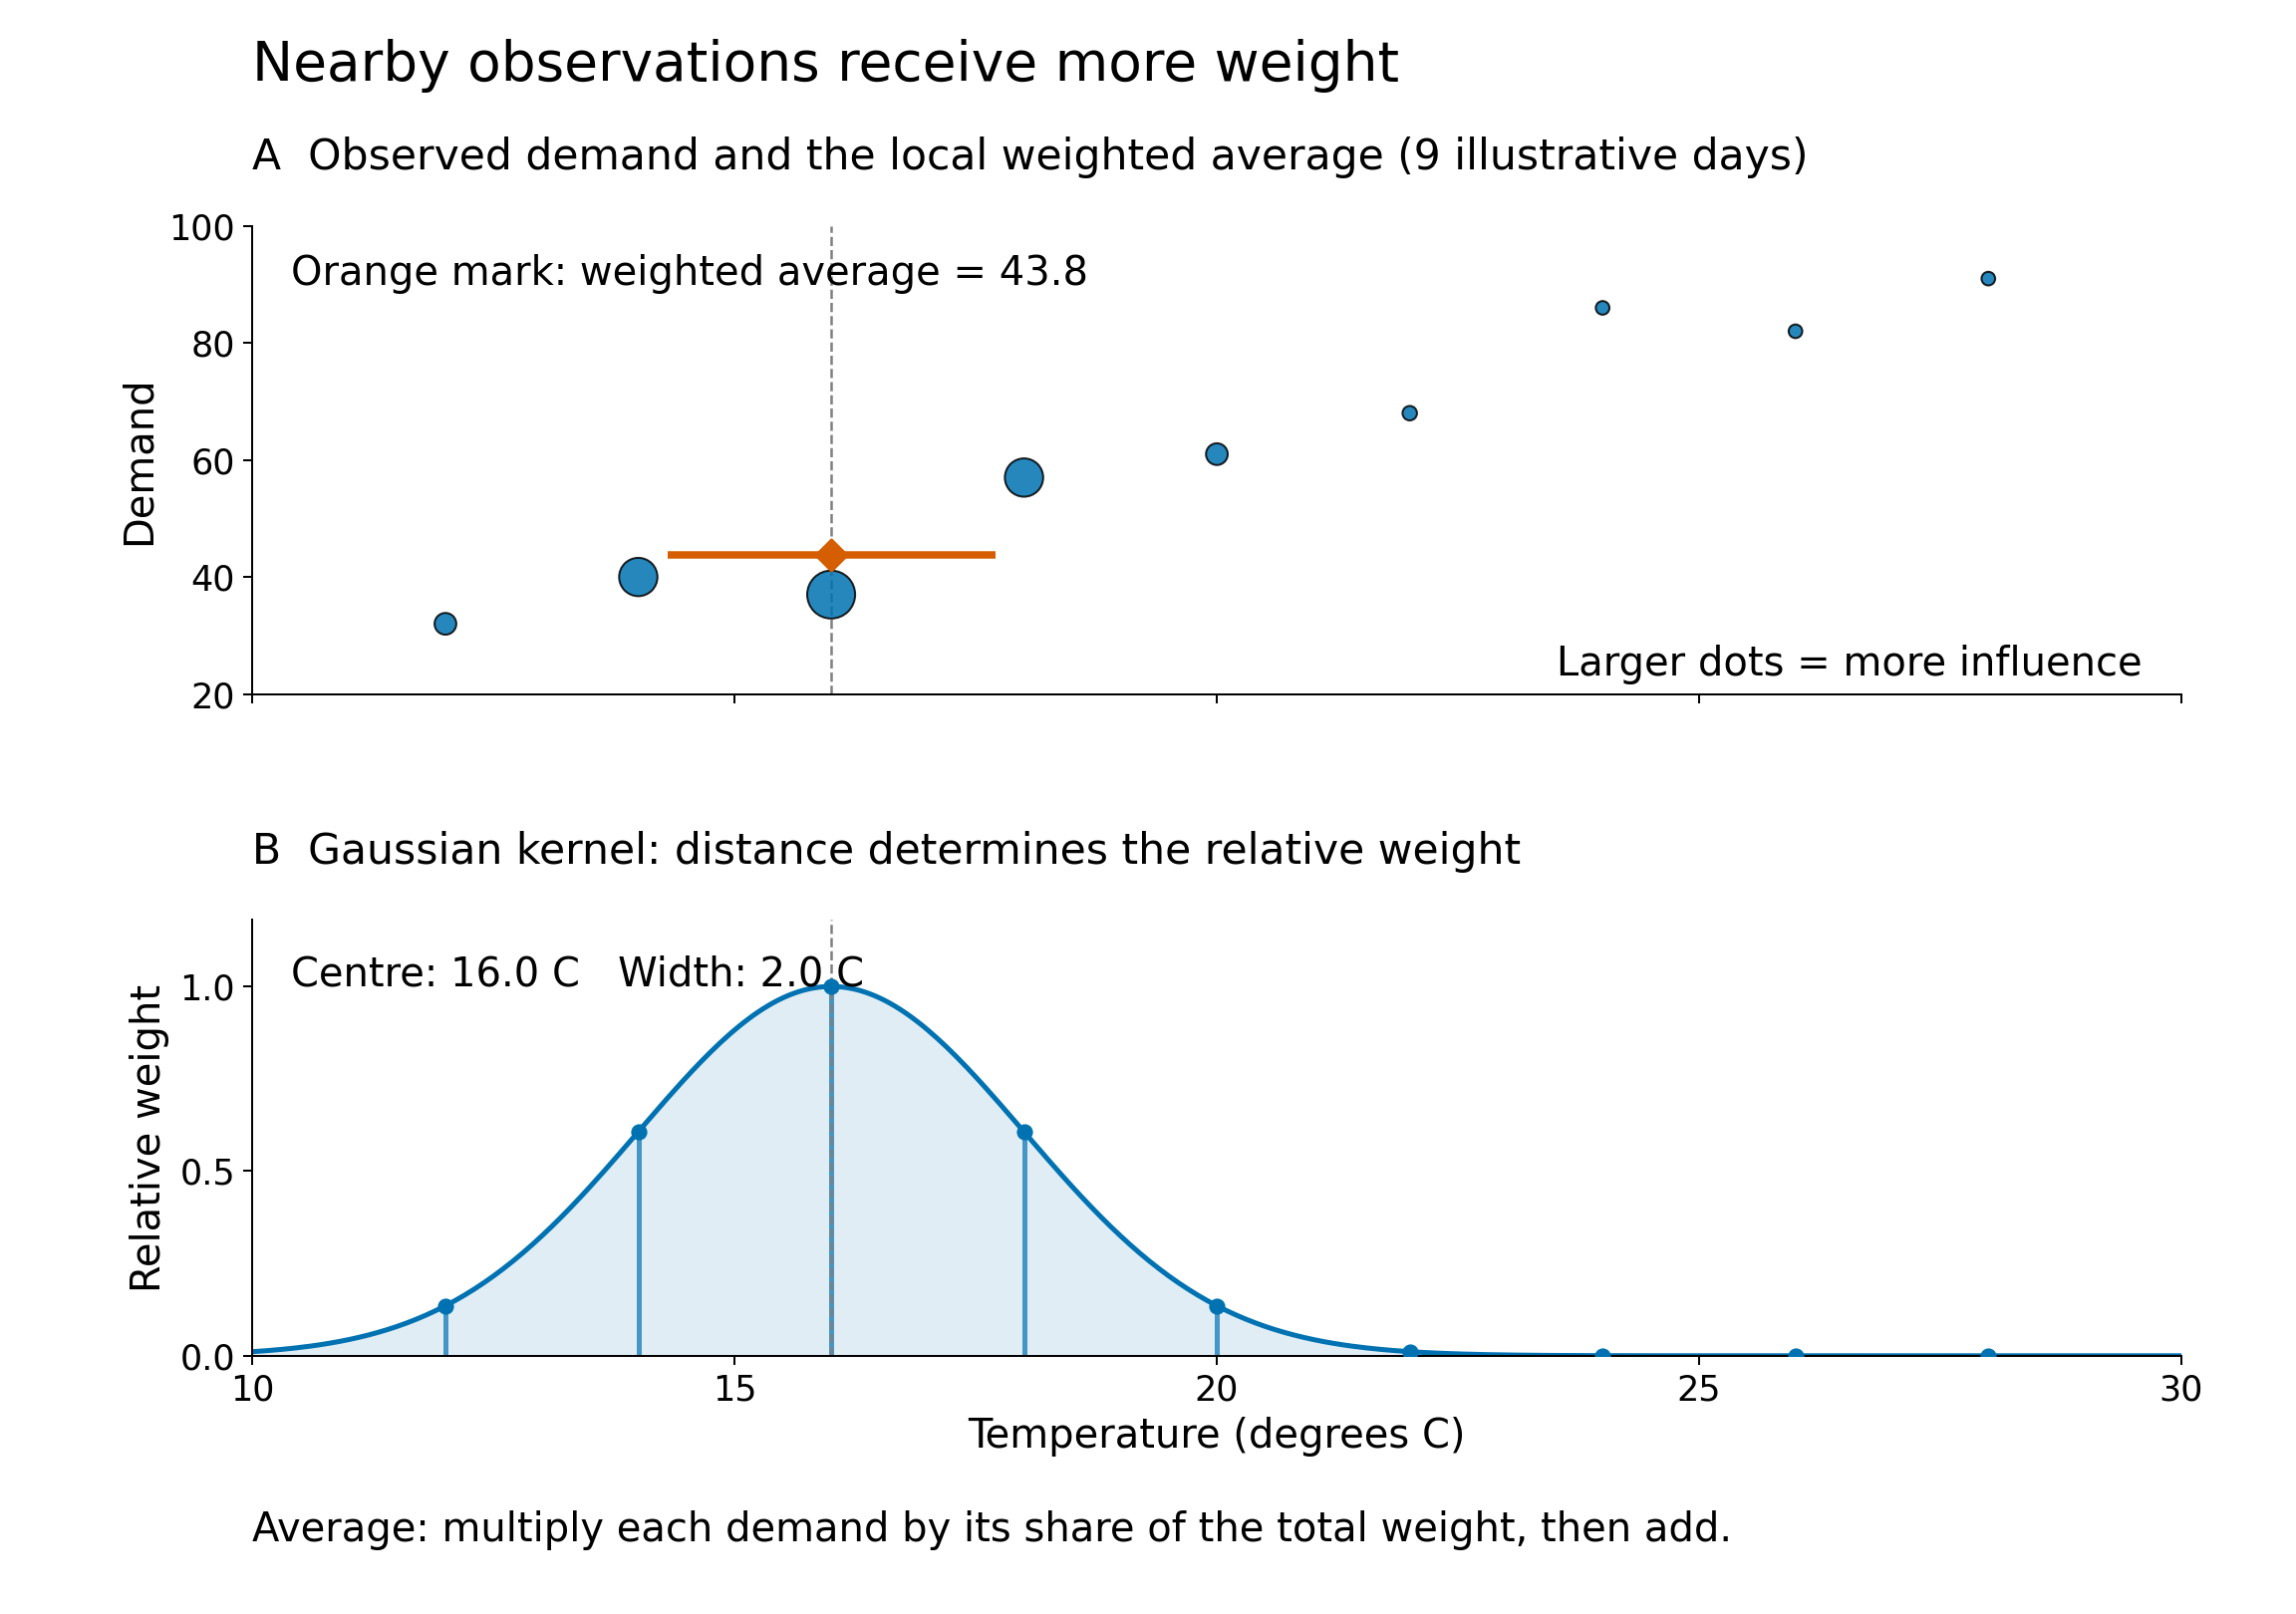

In [21]:
def draw_kernel_panels(x, y, centre, width):
    import numpy as np
    import matplotlib.pyplot as plt
    weights = np.exp(-0.5 * ((x-centre)/width)**2)
    shares = weights / weights.sum()
    estimate = float(shares @ y)
    grid = np.linspace(10, 30, 401)
    curve = np.exp(-0.5 * ((grid-centre)/width)**2)
    fig = plt.figure(figsize=(12.8, 9), dpi=100, facecolor='white')
    upper = fig.add_axes([.11,.57,.84,.29])
    lower = fig.add_axes([.11,.16,.84,.27], sharex=upper)
    fig.text(.11,.95,'Nearby observations receive more weight',fontsize=22,color='black')
    fig.text(.11,.895,'A  Observed demand and the local weighted average (9 illustrative days)',fontsize=17,color='black')
    upper.set(xlim=(10,30),ylim=(20,100),ylabel='Demand')
    upper.scatter(x,y,s=30+850*shares,c='#0072B2',alpha=.85,edgecolors='black',linewidths=.8,zorder=3)
    upper.axvline(centre,color='gray',ls='--',lw=1)
    upper.hlines(estimate,centre-1.7,centre+1.7,color='#D55E00',lw=3,zorder=4)
    upper.scatter([centre],[estimate],marker='D',s=80,c='#D55E00',zorder=5)
    upper.text(.02,.94,f'Orange mark: weighted average = {estimate:.1f}',transform=upper.transAxes,va='top',fontsize=16,color='black')
    upper.text(.98,.04,'Larger dots = more influence',transform=upper.transAxes,ha='right',fontsize=16,color='black')
    upper.tick_params(labelbottom=False)
    fig.text(.11,.465,'B  Gaussian kernel: distance determines the relative weight',fontsize=17,color='black')
    lower.set(xlim=(10,30),ylim=(0,1.18),xlabel='Temperature (degrees C)',ylabel='Relative weight')
    lower.fill_between(grid,0,curve,color='#0072B2',alpha=.12)
    lower.plot(grid,curve,color='#0072B2',lw=2)
    lower.vlines(x,0,weights,color='#0072B2',alpha=.7,lw=2)
    lower.scatter(x,weights,s=30,c='#0072B2',zorder=3)
    lower.axvline(centre,color='gray',ls='--',lw=1)
    lower.text(.02,.92,f'Centre: {centre:.1f} C   Width: {width:.1f} C',transform=lower.transAxes,va='top',fontsize=16,color='black')
    lower.set_yticks([0,.5,1]);lower.set_xticks([10,15,20,25,30])
    for ax in [upper,lower]:
        ax.spines[['top','right']].set_visible(False)
        ax.tick_params(labelsize=14)
        ax.xaxis.label.set_size(16);ax.yaxis.label.set_size(16)
    fig.text(.11,.045,'Average: multiply each demand by its share of the total weight, then add.',fontsize=16,color='black')
    return fig, dict(centre=float(centre),width=float(width),weights=weights.tolist(),shares=shares.tolist(),estimate=estimate)

fig,kernel_record=draw_kernel_panels(kernel_x,kernel_y,16.,2.)
save(16)
values["6.8A"]=kernel_record

### Interpretation

Both panels use the same temperatures. High lower-panel weights correspond to larger upper-panel dots. Moving the centre changes which observations contribute most. Widening the bell increases the relative influence of farther observations. The Gaussian profile is used here as relative weights. An SVM uses Gaussian similarities in a learned decision rule; the displayed local average is a separate transparent illustration.

### When to refer back at work

Refer here when interpreting Gaussian distance weights, width settings and normalized weighted averages. For an SVM, check the trained coefficients and model scaling as well as the kernel setting. The two-panel example uses a local weighted average to explain influence.

## Example 6.9 — SVR applies support-vector ideas to a numerical target

Support Vector Regression (SVR) predicts a number using a fitting rule that allows a chosen error tolerance.

Imagine predicting demand with an allowed miss of fifteen units. A miss of ten uses none of the error penalty; a miss of forty leaves twenty-five units beyond the allowance. The shaded strip around the fitted curve shows this allowance. In the small numerical code example the same calculation uses point one five instead of fifteen. A Pipeline packages scaling and the fitted model so the same preparation is applied whenever a prediction is made.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ L_\epsilon(y,f)=\max(0,|y-f|-\epsilon) $$

**absolute error:** distance from the observed number to its prediction

**epsilon:** the tolerated error width on each side

**positive remainder:** the part of the miss beyond the tolerated band

### 6.9.1 — Fit a small nonlinear SVR example

**Purpose and inputs.** Use a deterministic curved target with small constructed variation.

**Read the result.** Input scaling is fitted in the Pipeline before SVR.

In [22]:
rx=np.linspace(-2,2,30).reshape(-1,1);ry=rx[:,0]**2+.12*np.sin(8*rx[:,0]);svr=make_pipeline(StandardScaler(),SVR(kernel='rbf',C=10,epsilon=.15,gamma='scale')).fit(rx,ry)
grid=np.linspace(-2.1,2.1,160).reshape(-1,1);rf=svr.predict(grid);print('Support-vector count:',len(svr[-1].support_))

Support-vector count: 7


### 6.9.2 — Show the fitting tolerance band

**Purpose and inputs.** Draw prediction plus/minus epsilon and circle support observations.

**Read the result.** The epsilon band describes the fitting criterion.

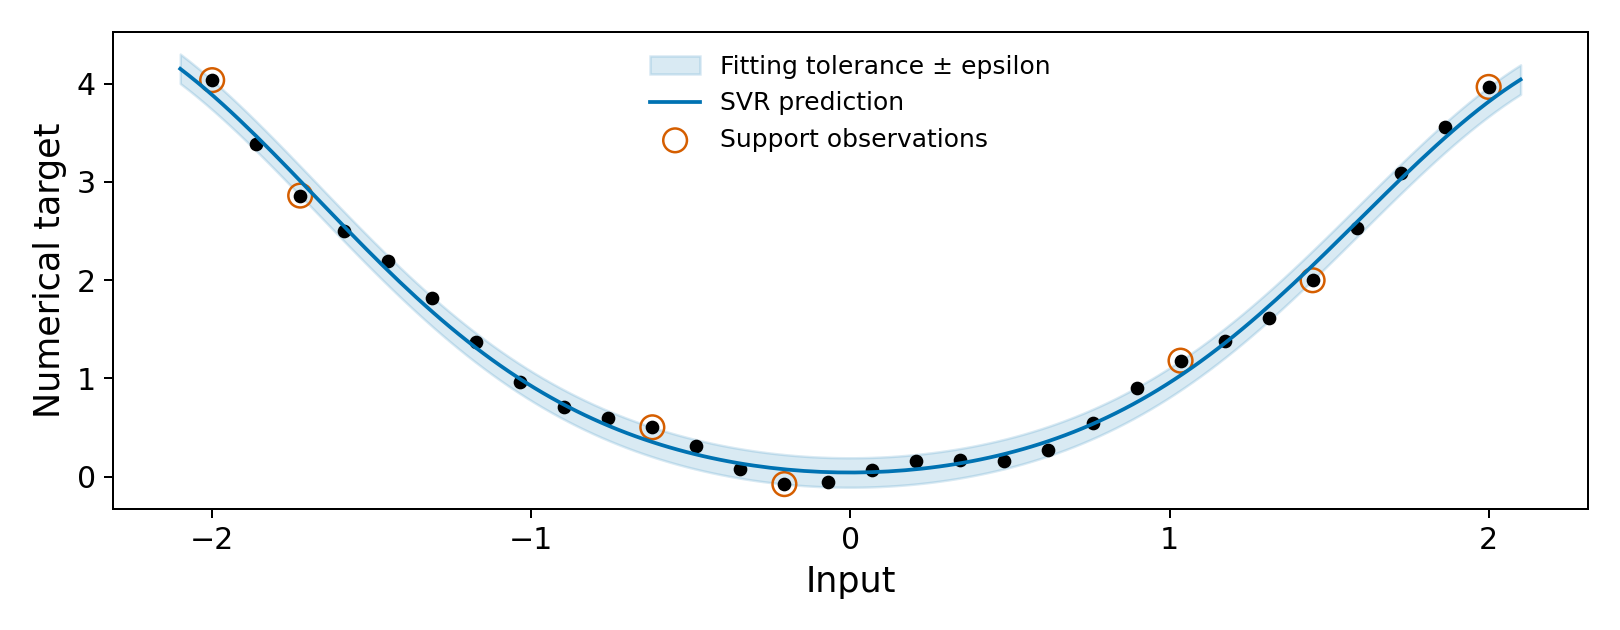

In [23]:
fig,ax=plt.subplots(figsize=(9,3.5));ax.fill_between(grid[:,0],rf-.15,rf+.15,color=BLUE,alpha=.15,label='Fitting tolerance ± epsilon');ax.plot(grid[:,0],rf,color=BLUE,label='SVR prediction');ax.scatter(rx[:,0],ry,color='black',s=20);support=svr[-1].support_;ax.scatter(rx[support,0],ry[support],facecolors='none',edgecolors=ORANGE,s=90,label='Support observations');ax.set(xlabel='Input',ylabel='Numerical target');ax.legend(fontsize=10);save(9)
values['6.9']={'epsilon':.15,'C':10,'support_count':len(support)}

### Interpretation

The toy example uses a nonlinear RBF (radial basis function) kernel: similarity falls as squared input distance increases. Gamma controls that distance scale. Training-fitted input scaling, C=10, epsilon=.15 and gamma=scale are stated settings. The band is a tolerance used in fitting, not an outcome probability interval. Its value uses target units; input scaling does not change those target units.

### When to refer back at work

Refer here for a numerical SVR task. Check input scaling, C, epsilon, kernel settings and training cost; choose them using validation appropriate to your target and information timing.

## Example 6.10 — One neural-network unit computes a weighted transformation

A neural-network unit combines input numbers with weights and a bias, then applies an activation function. A weight is an adjustable coefficient; a bias is an added adjustable constant. An activation transforms the combined number; ReLU (rectified linear unit) keeps a positive value and returns zero for a negative value.

Follow the boxes from left to right. First multiply each input by its weight, then add the contributions and the constant. Next apply the activation rule. Here the rule passes a positive total and changes a negative total to zero. The outgoing arrow carries that resulting number to the next calculation.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ z=w_1x_1+w_2x_2+b,\qquad h=\max(0,z) $$

**weighted sum z:** multiply matching inputs and weights, add products and bias

**activation:** apply the stated transformation to z

**output h:** the number passed to the next calculation

### 6.10.1 — Calculate a unit by hand and in code

**Purpose and inputs.** Use the stated two inputs, weights and bias.

**Read the result.** A unit has an explicit numerical operation that can be inspected.

In [24]:
nx=np.array([2.,1.]);nw=np.array([1.,-1.]);bias=.5;z=float(nw@nx+bias);h=max(0,z)
print('Weighted sum:',z,'Activated output:',h)
assert np.isclose(h,1.5)

Weighted sum: 1.5 Activated output: 1.5


### 6.10.2 — Draw the calculation chain

**Purpose and inputs.** Each box shows a numerical transformation.

**Read the result.** An arrow means that a computed value is passed to the next operation.

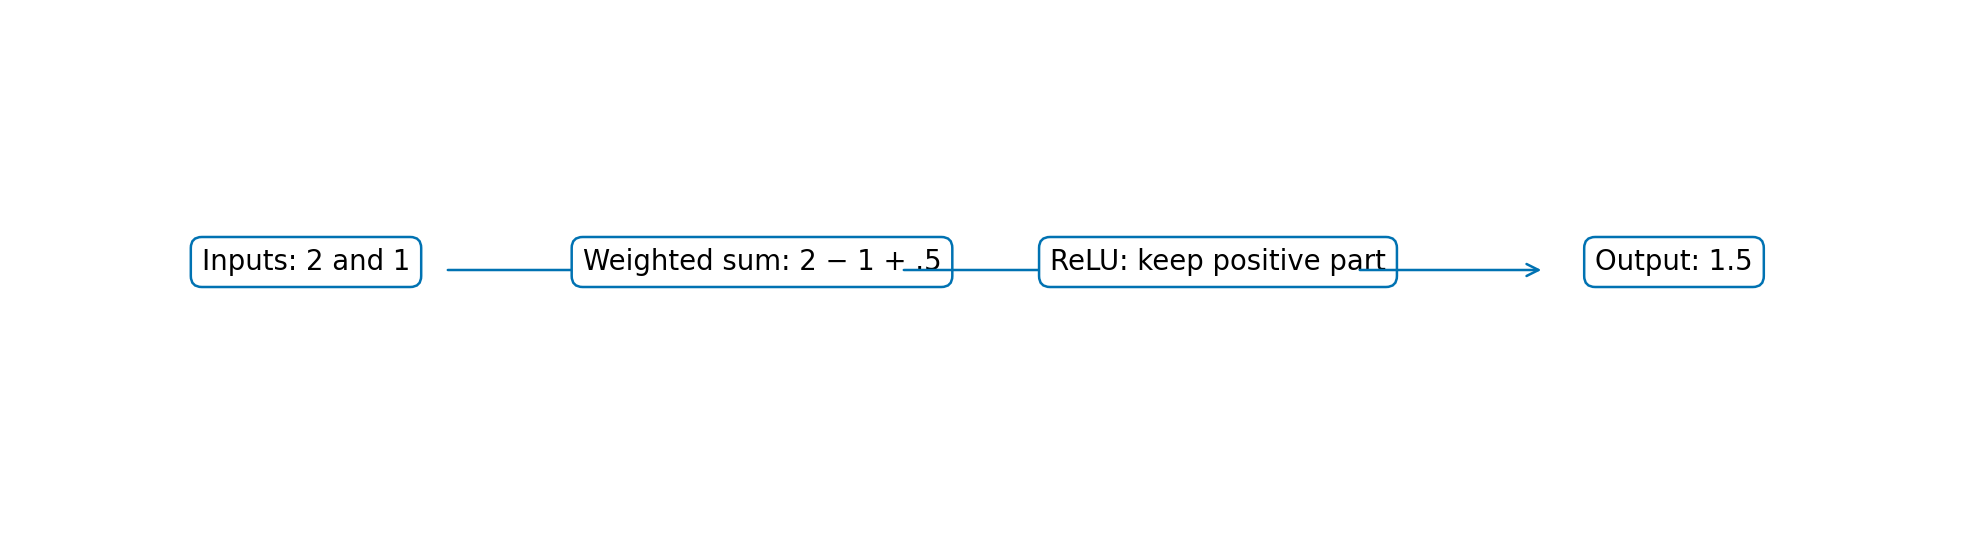

In [25]:
fig,ax=plt.subplots(figsize=(11,3));ax.axis('off');texts=['Inputs: 2 and 1','Weighted sum: 2 − 1 + .5','ReLU: keep positive part','Output: 1.5']
for j,s in enumerate(texts):
 ax.text(j,.5,s,ha='center',fontsize=11,bbox=dict(fc='white',ec=BLUE,boxstyle='round,pad=.4'))
 if j<3:ax.annotate('',(j+.72,.5),(j+.3,.5),arrowprops=dict(arrowstyle='->',color=BLUE))
ax.set(xlim=(-.6,3.6),ylim=(0,1));save(10)
values['6.10']={'weighted_sum':z,'output':h}

### Interpretation

For inputs (2,1), weights (1,-1) and bias .5, z=1.5 and the ReLU output is 1.5. Weights, bias and activation together define the unit. A nonlinear activation lets a multilayer network form nonlinear relationships.

### When to refer back at work

Refer here to read the input/weight shapes of a dense layer, interpret a bias and understand how an activation changes its output.

## Example 6.11 — Layers compose transformations: a folding analogy

A layer is one stage of numerical calculations. Its outputs become the next layer's inputs. Hidden layers are the stages between the original inputs and final output.

Watch the marked sheet. After one fold, the marks occupy a different arrangement; the next fold works on that new arrangement. A network layer similarly calculates new numbers from the numbers it receives. Those new numbers become the next layer's inputs. In the code, a matrix is simply a table of weights, with one row for each unit's calculation. Training revises those weights while keeping the chosen layer arrangement.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

### 6.11.1 — Compute two hidden layers and the output

**Purpose and inputs.** Use fixed illustrative matrices to keep every intermediate value inspectable.

**Read the result.** The network has input size 2, hidden sizes 2 and 2, and output size 1.

In [26]:
W1=np.array([[1.,-1.],[.5,.5]]);b1=np.array([.5,0.]);W2=np.array([[1.,.5],[-1.,1.]]);b2=np.array([0.,.2]);W3=np.array([1.,-.5]);b3=.1
h1=np.maximum(0,W1@nx+b1);h2=np.maximum(0,W2@h1+b2);prediction=float(W3@h2+b3)
print('Input:',nx,'Hidden 1:',h1,'Hidden 2:',h2,'Prediction:',prediction)

Input: [2. 1.] Hidden 1: [1.5 1.5] Hidden 2: [2.25 0.2 ] Prediction: 2.25


### 6.11.2 — Draw fixed layer values and directed connections

**Purpose and inputs.** Display two hidden layers and the output layer.

**Read the result.** The diagram labels computed values; weights determine how they were combined.

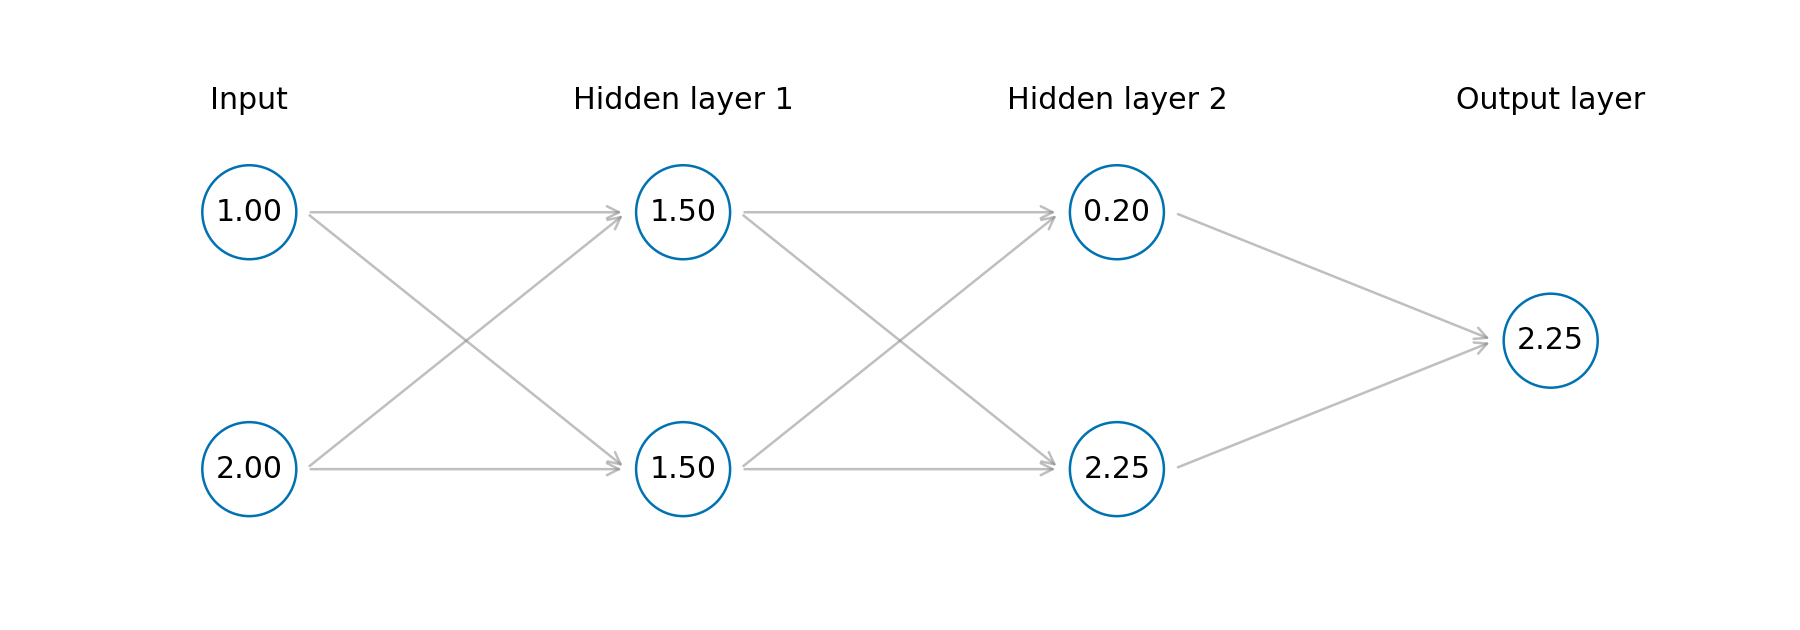

In [27]:
fig,ax=plt.subplots(figsize=(10,3.5));ax.axis('off');layers=[nx,h1,h2,np.array([prediction])]
for j,vals in enumerate(layers):
 ys=np.linspace(.25,.75,len(vals)) if len(vals)>1 else [.5]
 for yi,value in zip(ys,vals):ax.text(j,yi,f'{value:.2f}',ha='center',va='center',fontsize=12,bbox=dict(boxstyle='circle,pad=.45',fc='white',ec=BLUE))
 ax.text(j,.95,['Input','Hidden layer 1','Hidden layer 2','Output layer'][j],ha='center',fontsize=12)
 if j:
  prev=np.linspace(.25,.75,len(layers[j-1])) if len(layers[j-1])>1 else [.5]
  for yp in prev:
   for yc in ys:ax.annotate('',(j-.13,yc),(j-1+.13,yp),arrowprops=dict(arrowstyle='->',color='gray',alpha=.5))
ax.set(xlim=(-.5,3.5),ylim=(0,1.1));save(11)
values['6.11']={'hidden1':h1.tolist(),'hidden2':h2.tolist(),'prediction':prediction,'parameterized_layers':3}
np.savez(Q/'network_values.npz',input=nx,h1=h1,h2=h2,prediction=prediction)

### 6.11.3 — Construct the paper-fold analogy

**Purpose and inputs.** Apply two stated geometric rotations to a marked grid.

**Read the result.** This is a representation analogy: numerical network layers compose transformations; training adjusts their parameters.

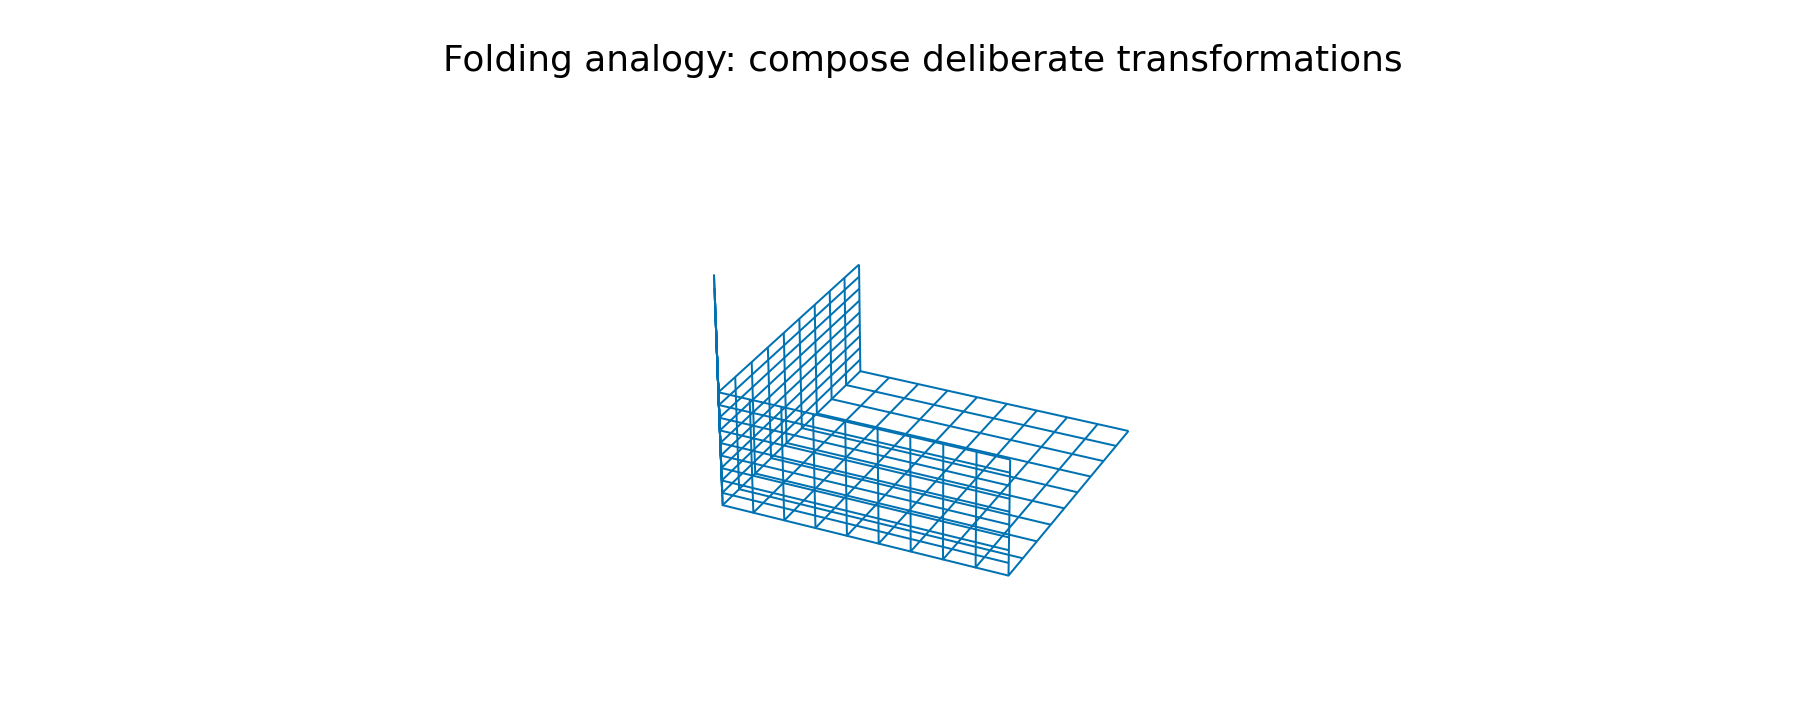

In [28]:
fu,fv=np.meshgrid(np.linspace(-1,1,19),np.linspace(-1,1,19));fx=fu.copy();fy=fv.copy();fz=np.zeros_like(fu)
left=fu<0;fx[left]=0;fz[left]=-fu[left]
bottom=fv<0;fy[bottom]=0;fz[bottom]+=-fv[bottom]
fig=plt.figure(figsize=(10,4));fax=fig.add_subplot(111,projection='3d');fax.plot_wireframe(fx,fy,fz,color=BLUE,linewidth=.8);fax.view_init(28,-65);fax.set_axis_off();fax.set_title('Folding analogy: compose deliberate transformations')
plt.savefig(G/'ex6_11_fold.png',dpi=180,facecolor='white');display(NotebookImage(filename=str(G/'ex6_11_fold.png')));plt.close()

### Interpretation

Imagine a sheet with marked points. One deliberate fold changes how the marks are arranged; another fold transforms that arrangement again. A layer represents a numerical transformation in this analogy. The demonstrated network has two hidden layers and one output layer: three parameterized layers, plus the input display. Training revisits this fixed architecture and adjusts its parameters to improve the target result.

### When to refer back at work

Refer here to inspect network dimensions and distinguish the number of layers from the number of training updates. The paper fold is a representation analogy, not a simulation of how parameters are fitted.

## Example 6.12 — Backpropagation computes gradients through the layers

Backpropagation works backward through a network's calculations to determine how each adjustable weight affects prediction error. Training uses that information to adjust weights.

Follow the network from input to prediction. Compare the prediction with the observed outcome. Then trace backward to determine how each weight affects that error. Backpropagation calculates those effects; training uses them to adjust weights and try again.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ J=\tfrac12(\hat y-y)^2,\quad h=\max(0,wx),\quad\hat y=vh $$

**forward pass:** compute the hidden value, prediction and loss

**backward pass:** compute loss changes with respect to each weight

**parameter update:** use those gradients in a stated optimization step

### 6.12.1 — Compute the forward values and weight gradients

**Purpose and inputs.** Use a positive hidden preactivation, whose ReLU slope is one.

**Read the result.** The output error is -2; local sensitivities transmit it to the two weights.

In [29]:
ix=2.;iw=.5;iv=1.;target=3.;hidden=max(0,iw*ix);pred=iv*hidden;err=pred-target
old_loss=.5*err**2;dv=err*hidden;dw=err*iv*(1. if iw*ix>0 else 0.)*ix
print('Prediction, loss:',pred,old_loss,'Gradients w,v:',dw,dv)

Prediction, loss: 1.0 2.0 Gradients w,v: -4.0 -2.0


### 6.12.2 — Update both weights using the old gradients

**Purpose and inputs.** Take one simultaneous update with learning rate .1.

**Read the result.** New loss is .3528 in this explicit example.

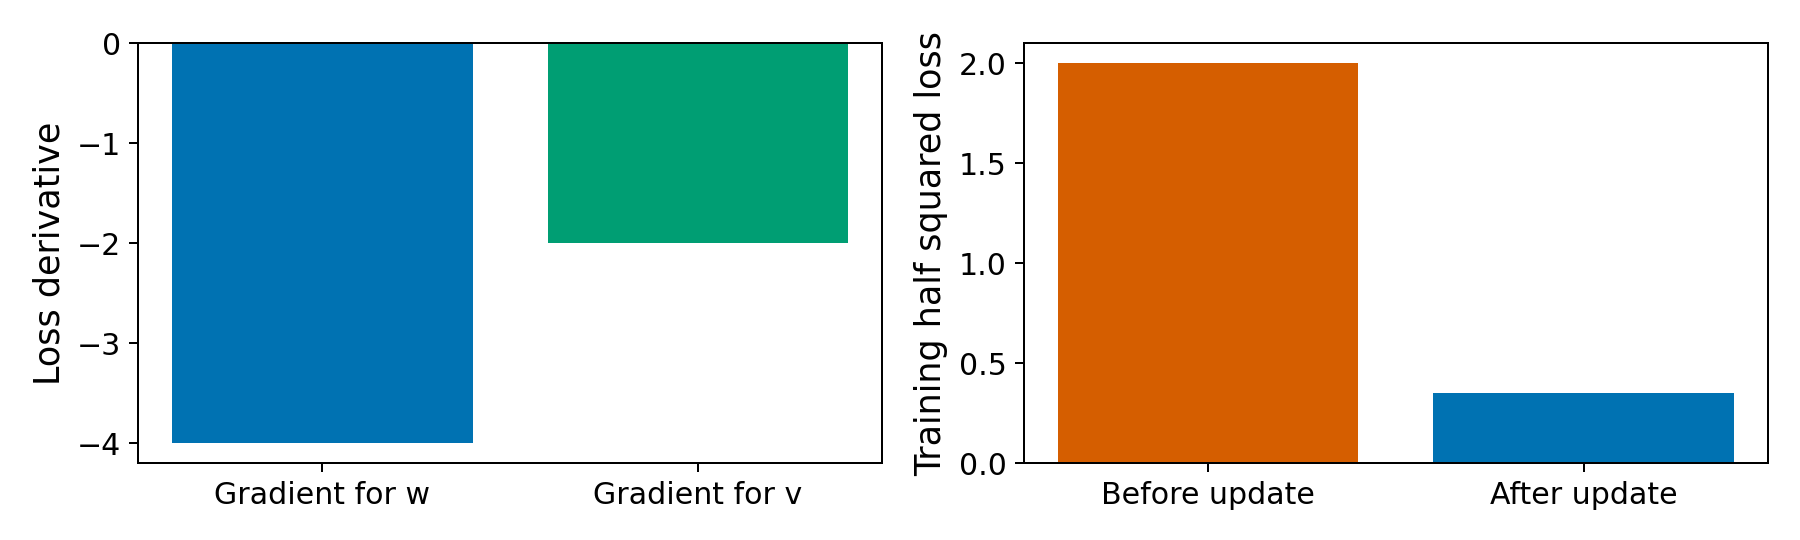

In [30]:
neww=iw-.1*dw;newv=iv-.1*dv;newpred=newv*max(0,neww*ix);newloss=.5*(newpred-target)**2
assert np.isclose(newloss,.3528)
fig,axs=plt.subplots(1,2,figsize=(10,3));axs[0].bar(['Gradient for w','Gradient for v'],[dw,dv],color=[BLUE,GREEN]);axs[0].axhline(0,color='black',lw=.8);axs[0].set(ylabel='Loss derivative');axs[1].bar(['Before update','After update'],[old_loss,newloss],color=[ORANGE,BLUE]);axs[1].set(ylabel='Training half squared loss');save(12)
values['6.12']={'grad_w':dw,'grad_v':dv,'old_loss':old_loss,'new_loss':newloss,'new_prediction':newpred}

### Interpretation

In the positive-ReLU example x=2,w=.5,v=1,y=3, prediction=1 and loss=2. The gradients are dJ/dv=-2 and dJ/dw=-4. A simultaneous .1 gradient step gives w=.9 and v=1.2, prediction 2.16 and loss .3528. The backward pass propagates derivative information; the forward model remains a sequence of numerical transformations.

### When to refer back at work

Refer here to connect a gradient-descent update to neural-network training, inspect derivative signs and separate forward computation, gradient computation and parameter updates.

## Example 6.13 — Sequence order can matter to a prediction

A sequence is an ordered set of observations. A state is a numerical summary carried from one step to the next. A recurrent computation updates that state using the preceding state and the current input.

Imagine demand jumped four days ago, compared with demand jumping today. The average of the four days can match, while the recent situation differs. Watch how an early input gradually fades in the running summary. A late input remains larger at the end because fewer update steps have reduced it.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ s_t=0.5s_{t-1}+x_t $$

**old state:** the summary retained from the preceding step

**current input:** the next number in the ordered sequence

**new state:** the retained half of the old state plus the input

### 6.13.1 — Process the same numbers in different orders

**Purpose and inputs.** Start at zero state and update through each sequence.

**Read the result.** Different final states reveal that the computation retains order.

In [31]:
seqs=[np.array([1.,0.,0.,0.]),np.array([0.,0.,0.,1.])];states=[]
for sequence in seqs:
 st=0.;hist=[]
 for item in sequence:st=.5*st+item;hist.append(st)
 states.append(hist)
print('Sequence means:',[s.mean() for s in seqs],'Final states:',[s[-1] for s in states])

Sequence means: [0.25, 0.25] Final states: [0.125, 1.0]


### 6.13.2 — Compare the numerical memories

**Purpose and inputs.** Use the same axes and update rule.

**Read the result.** Only input order changes.

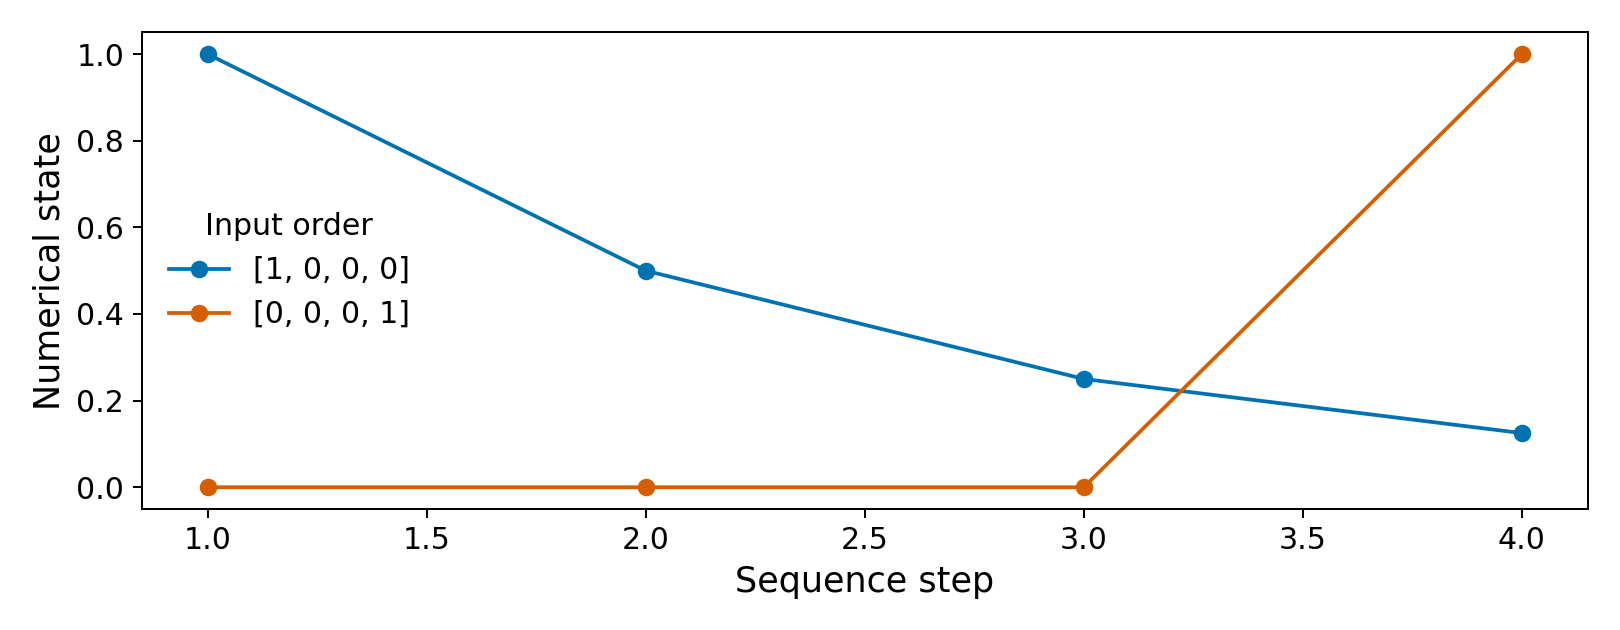

In [32]:
fig,ax=plt.subplots(figsize=(9,3.5))
for sequence,hist,col in zip(seqs,states,[BLUE,ORANGE]):ax.plot(range(1,5),hist,'o-',color=col,label=str(sequence.astype(int).tolist()))
ax.set(xlabel='Sequence step',ylabel='Numerical state');ax.legend(title='Input order');save(13)
values['6.13']={'final_states':[s[-1] for s in states]}

### Interpretation

The sequences (1,0,0,0) and (0,0,0,1) contain the same numbers and have the same mean. Their final recurrent states are .125 and 1. The stated update weights recent inputs more heavily. A trained recurrent model learns a specified sequence mapping using data and evaluation.

### When to refer back at work

Refer here when a feature summary discards timing that may matter, such as the order of recent demand observations. Define the information cutoff and target before choosing a sequence model.

## Example 6.14 — LSTM controls retained, incoming and output information

Long Short-Term Memory (LSTM) is a neural network for ordered inputs. It carries numerical memory between observations and learns how much old and new information to retain.

Think of memory as a running numerical note about earlier observations. A forget gate controls the part retained from the old note, an input gate controls the new contribution, and an output gate controls the amount passed onward. Training learns how to calculate these gates from the sequence.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

$$ c_t=f_tc_{t-1}+i_tg_t,\qquad h_t=o_t\tanh(c_t) $$

**c previous:** previous memory state

**f times c:** retained old memory

**i times g:** incoming candidate contribution

**c new:** updated memory

**o times tanh c:** exposed output state

### 6.14.1 — Specify gates and candidate transformation

**Purpose and inputs.** Use candidate inputs 0,0,1,1,0,0 and initial cell memory zero.

**Read the result.** Constant gates correspond to a valid fixed choice of gate weights and biases.

In [33]:
sigmoid=lambda z:1/(1+np.exp(-z))
f=float(sigmoid(np.log(.8/.2)));ig=float(sigmoid(np.log(.2/.8)));og=float(sigmoid(np.log(.9/.1)))
sequence=np.array([0.,0.,1.,1.,0.,0.]);cell=0.;cell_rows=[]
for t,item in enumerate(sequence,1):
 candidate=float(np.tanh(item));retained=f*cell;incoming=ig*candidate;cell=retained+incoming;output=og*np.tanh(cell)
 cell_rows.append(dict(step=t,input=item,retain=retained,incoming=incoming,cell=cell,output=output))
cell_table=pd.DataFrame(cell_rows);print(cell_table.round(4))

   step  input  retain  incoming    cell  output
0     1    0.0  0.0000    0.0000  0.0000  0.0000
1     2    0.0  0.0000    0.0000  0.0000  0.0000
2     3    1.0  0.0000    0.1523  0.1523  0.1360
3     4    1.0  0.1219    0.1523  0.2742  0.2408
4     5    0.0  0.2193    0.0000  0.2193  0.1943
5     6    0.0  0.1755    0.0000  0.1755  0.1563


### 6.14.2 — Display the cell-state contributions and exposed output

**Purpose and inputs.** Plot retained and incoming memory contributions separately.

**Read the result.** The black output curve applies the output gate and tanh to the resulting memory.

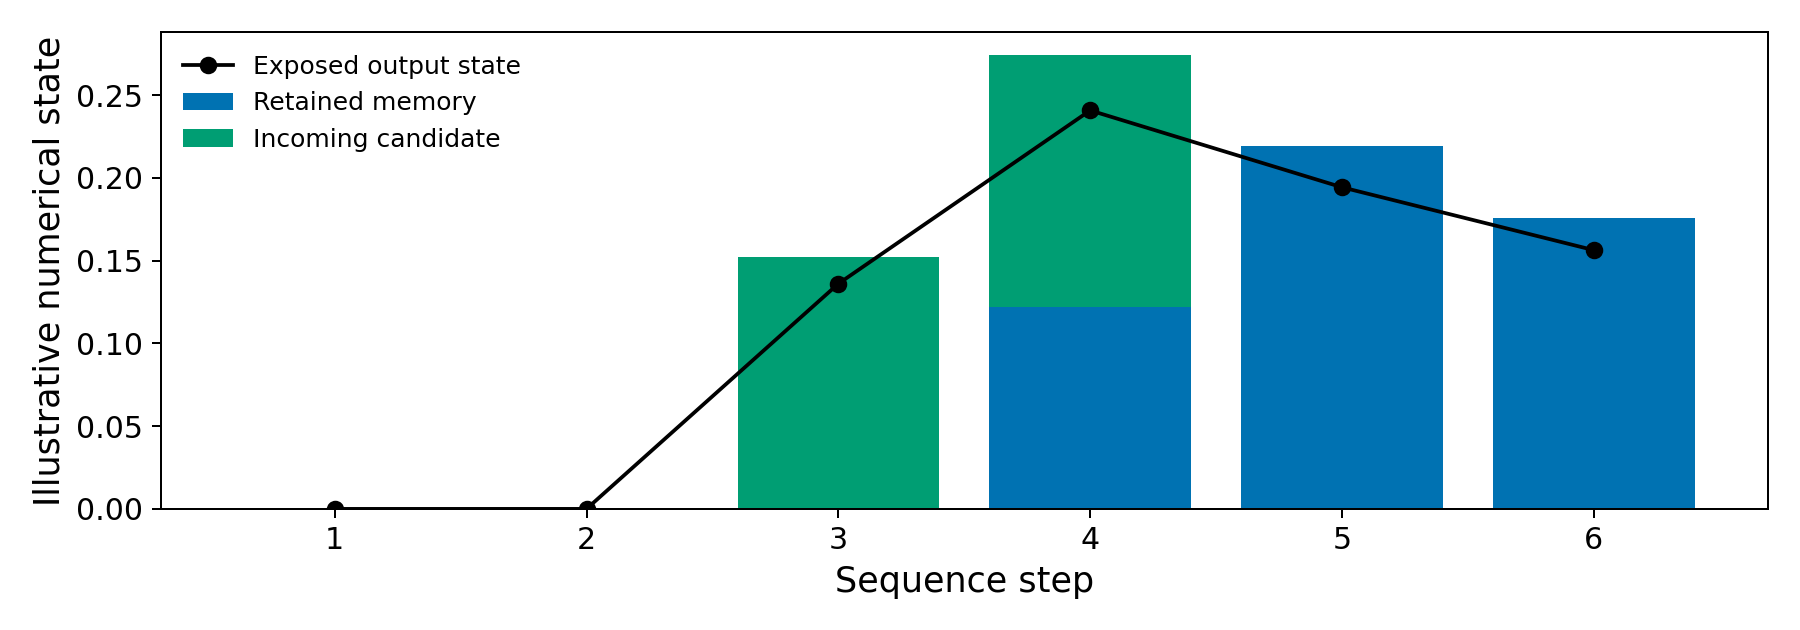

In [34]:
fig,ax=plt.subplots(figsize=(10,3.5));ax.bar(cell_table.step,cell_table.retain,color=BLUE,label='Retained memory');ax.bar(cell_table.step,cell_table.incoming,bottom=cell_table.retain,color=GREEN,label='Incoming candidate');ax.plot(cell_table.step,cell_table.output,'ko-',label='Exposed output state');ax.set(xlabel='Sequence step',ylabel='Illustrative numerical state');ax.legend(fontsize=10);save(14)
values['6.14']={'forget_gate':f,'input_gate':ig,'output_gate':og,'records':cell_rows}
cell_table.to_csv(Q/'lstm_forward_values.csv',index=False)

### Interpretation

A complete LSTM learns gate and candidate parameters from sequence data. This fixed-parameter forward example sets gates .8,.2,.9 through constant sigmoid inputs and takes candidate tanh(x). It shows the actual cell-state and output calculations transparently. The final output can feed a prediction layer. The example illustrates mechanism rather than measured forecasting improvement.

### When to refer back at work

Refer here to distinguish cell memory from exposed output and to inspect input/sequence/state shapes before reading a library LSTM implementation. Evaluate future predictions chronologically and compare with simple alternatives.

## Example 6.15 — Prepare a time-series window for a sequence model

A sequence input window groups the most recent observations into an ordered input for a later target. In a common LSTM interface, input dimensions are samples, time steps and features.

Read the first row of the window picture: ten, twelve and eleven are the three earlier observations; fourteen is the later value to predict. Shift one place right: twelve, eleven and fourteen now predict thirteen. Each row is one sample. Three positions within a row are three time steps. One number at each position means one feature. This is why the array has five rows of examples, three ordered positions and one feature per position.

**Optional calculation reference.** The following expressions and code preserve the working demonstration for later use. In class, focus on what the picture changes and why.

**sample:** one input window and its target

**time steps:** ordered observations inside that window

**features:** variables observed at each step

### 6.15.1 — Construct ordered windows and subsequent targets

**Purpose and inputs.** Use values 10,12,11,14,13,15,16,15 with three-step inputs.

**Read the result.** Each target occurs immediately after its input window.

In [35]:
series=np.array([10.,12.,11.,14.,13.,15.,16.,15.]);window=3
sequence_X=np.array([series[j-window:j] for j in range(window,len(series))])[...,None]
sequence_y=series[window:]
assert sequence_X.shape==(5,3,1)
print('Shape:',sequence_X.shape);print('First input:',sequence_X[0,:,0],'First target:',sequence_y[0])

Shape: (5, 3, 1)
First input: [10. 12. 11.] First target: 14.0


### 6.15.2 — Draw the windows on the original observation order

**Purpose and inputs.** Input positions and targets use different markers.

**Read the result.** Each row has three earlier inputs and one later target.

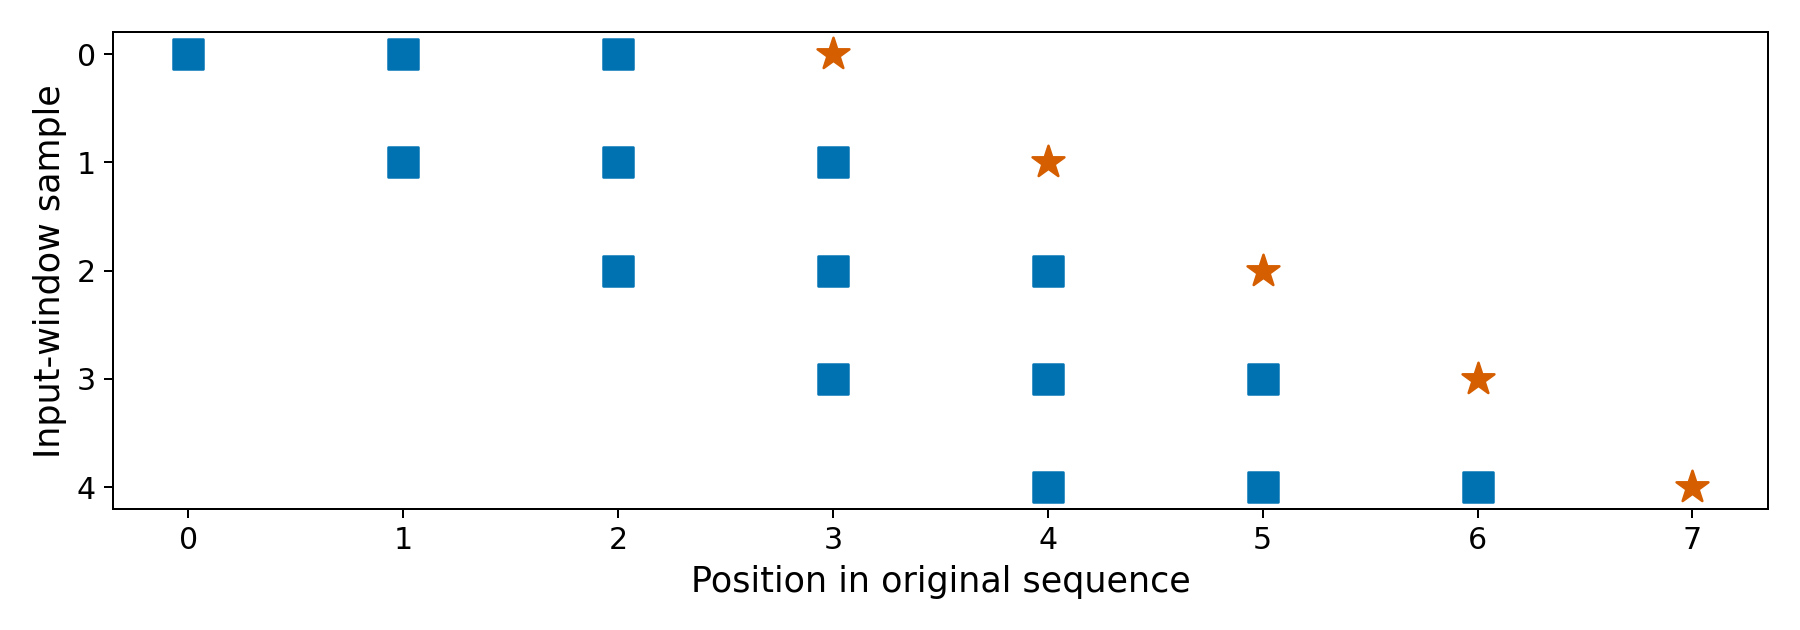

3755

In [36]:
fig,ax=plt.subplots(figsize=(10,3.5))
for row in range(5):
 inputs=np.arange(row,row+3);ax.scatter(inputs,np.repeat(row,3),marker='s',color=BLUE,s=140);ax.scatter(row+3,row,marker='*',color=ORANGE,s=180)
ax.set(xlabel='Position in original sequence',ylabel='Input-window sample',yticks=range(5),xticks=range(8));ax.invert_yaxis();save(15)
values['6.15']={'shape':list(sequence_X.shape),'targets':sequence_y.tolist()}
(Q/'worked_values.json').write_text(json.dumps(values,indent=2))

### Interpretation

With eight observed values and window length three, there are five next-value examples. The input shape is (5,3,1). The first three targets form an illustrative training block and the last two a later block. Overlap in earlier inputs is compatible with forecasting when every target and input respects its origin.

### When to refer back at work

Refer here when reshaping a chronological dataset for an LSTM. Specify target, origin, horizon and known input variables; fit preprocessing on training data, select architecture using validation and evaluate later outcomes. These illustrations add no project model requirements.

## Final project reminder

The newly introduced Gradient Boosting, SVM/SVR and neural-network illustrations are conceptual extensions. Follow the existing selected project notebook's requirements: the four required model families remain OLS, Ridge, Lasso and Random Forest. There is no new Lecture 6 homework.

Choose one of the released cases: healthcare, finance/banking or next-day bike-sharing demand/business operations. The instructor will open a Blackboard project submission link. Current syllabus deadline: **Sunday, May 2, 2027, 11:59 PM CDT**. The project remains 200 points: substantive attempts across all required items earn at least 100; the remaining 100 reward correct steps, completeness and quality.